# Investigação do MLP (autor: marina)

Notebook de investigação do `MLPClassifier`, comparável com os demais modelos do grupo:
mesma tabela `features`, mesma divisão (treino 2021–2022, validação 2023), mesmos folds
temporais (`src/modelagem/validacao.py`), mesmas métricas (PR-AUC principal, Recall@50,
Recall@100, ROC-AUC; `ARCHITECTURE.md`, seção 5) e semente 42. Todas as funções de treino e
avaliação vêm de `src.modelagem.treino` e `src.modelagem.pipeline`; o que é novo fica aqui.

Regras deste notebook:

- O **teste de 2024 não é usado** aqui, nem para olhar: a parte `teste` é descartada logo no setup.
  Ele pertence só ao `registrar_campeao` oficial.
- A melhor configuração é escolhida pelo **PR-AUC médio da CV temporal**. A validação de 2023 é
  reportada, mas não escolhe hiperparâmetro.
- Todo run no MLflow leva as tags `autor=marina` e `modelo=mlp`. Os pisos (Regressão Logística
  padrão e heurística de recorrência) são calculados aqui **sem** registrar runs, para não duplicar
  os runs oficiais do experimento `01_baseline`.
- O pré-processamento é o do repositório (`montar_pipeline`): mediana + `StandardScaler` nas
  numéricas e one-hot nas categóricas. A escala importa para o MLP: o gradiente e a regularização
  L2 (`alpha`) tratam todas as entradas na mesma escala.
- **Métrica extra** (só aqui, sem mudar `src/`): além do Recall@k, a **precisão@k** (acertos entre
  os k primeiros ÷ k, por trimestre, média dos trimestres; já devolvida por `metricas.avaliar`) e o
  **teto do Recall@k** (k ÷ positivos do trimestre, média dos trimestres). Com cerca de 350
  positivos por trimestre em `y_vitima`, o Recall@50 não pode passar de ~0,14 para nenhum modelo.

Execução (dentro do container, como os notebooks 01 e 02):

```bash
docker compose --profile dev run --rm -T -v "$PWD/reports:/app/reports" -w /app/notebooks jupyter \
    jupyter nbconvert --to notebook --execute --inplace modelo_mlp.ipynb --ExecutePreprocessor.timeout=-1
```

## 1. Setup

In [1]:
from pathlib import Path
import sys
import time
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, display

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)
pd.set_option("display.width", 180, "display.max_columns", 40, "display.precision", 3)
plt.rcParams.update({"figure.figsize": (9, 4), "axes.grid": True, "grid.alpha": .3})

# O notebook roda de notebooks/ (Jupyter ou nbconvert); os dados ficam em ../data.
RAIZ = Path.cwd().parent if (Path.cwd().parent / "data").exists() else Path("/app")
sys.path.insert(0, str(RAIZ))

import mlflow
from sklearn.base import clone
from sklearn.exceptions import ConvergenceWarning
from sklearn.metrics import average_precision_score, roc_auc_score
from sklearn.model_selection import StratifiedKFold

from src.modelagem import metricas
from src.modelagem import treino as T
from src.modelagem.pipeline import SEMENTE, montar_pipeline, modelos
from src.modelagem.treino import (ESPACOS, _cv, _cv_estratificado, _dados, _parametros, _rodar, _xy,
                                  carregar_features, score_heuristica)

MODELO, AUTOR = "mlp", "marina"
TAGS = {"autor": AUTOR, "modelo": MODELO}
ALVO = "y_vitima"
FIG = RAIZ / "reports" / "figuras" / MODELO
EXP = RAIZ / "reports" / "experimentos"
FIG.mkdir(parents=True, exist_ok=True)
EXP.mkdir(parents=True, exist_ok=True)

T._mlflow()
print("MLflow:", mlflow.get_tracking_uri(), "| semente:", SEMENTE)

/usr/local/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


MLflow: http://mlflow:5000 | semente: 42


In [2]:
# src.modelagem.metricas troca o backend para Agg (feito para o container sem display); de volta ao inline
%matplotlib inline


def salvar(fig, nome):
    """Grava a figura em reports/figuras/mlp/ e mostra no notebook."""
    fig.tight_layout()
    fig.savefig(FIG / nome, dpi=110)
    plt.show()


def com_avisos(fn, *args, **kwargs):
    """Roda fn e conta os ConvergenceWarning emitidos (o filtro global de UserWarning os esconderia)."""
    with warnings.catch_warnings(record=True) as avisos:
        warnings.simplefilter("always", ConvergenceWarning)
        saida = fn(*args, **kwargs)
    return saida, sum(issubclass(a.category, ConvergenceWarning) for a in avisos)

In [3]:
features = carregar_features()


def preparar(alvo):
    """Partes e folds do alvo, sem a parte de teste (2024 não é usado neste notebook)."""
    _, partes, folds = _dados(alvo, features)
    partes = {k: v for k, v in partes.items() if k != "teste"}
    return partes, folds


partes, folds = preparar(ALVO)
Xtr, ytr = _xy(partes["treino"], ALVO)
Xv, yv = _xy(partes["validacao"], ALVO)
tri_tr = partes["treino"]["trimestre"].to_numpy()
tri_v = partes["validacao"]["trimestre"]

resumo = pd.DataFrame({
    nome: {"linhas": len(p), "local_id": p["local_id"].nunique(),
           "trimestres": f"{p['trimestre'].min()}–{p['trimestre'].max()}",
           "positivos": int(p[ALVO].sum()), "prevalência": round(p[ALVO].mean(), 4)}
    for nome, p in partes.items()}).T
display(resumo)
N_ENTRADAS = montar_pipeline(features, MODELO).named_steps["prep"].fit(Xtr).transform(Xtr.head()).shape[1]
print("colunas de entrada:", Xtr.shape[1], "| colunas depois do pré-processamento:", N_ENTRADAS)
print("folds temporais:", [(f"{tri_tr[tr].min()}–{tri_tr[tr].max()}", tri_tr[te][0]) for tr, te in folds])
print("prevalência na validação de cada fold:", [round(ytr.iloc[te].mean(), 3) for _, te in folds])

,linhas,local_id,trimestres,positivos,prevalência
treino,13384,1673,2021Q1–2022Q4,1989,0.149
validacao,6692,1673,2023Q1–2023Q4,1392,0.208


colunas de entrada: 48 | colunas depois do pré-processamento: 142
folds temporais: [('2021Q1–2021Q4', '2022Q1'), ('2021Q1–2022Q1', '2022Q2'), ('2021Q1–2022Q2', '2022Q3'), ('2021Q1–2022Q3', '2022Q4')]
prevalência na validação de cada fold: [np.float64(0.137), np.float64(0.167), np.float64(0.164), np.float64(0.155)]


## 2. Pisos: Regressão Logística padrão e heurística de recorrência

Os dois pisos do `ARCHITECTURE.md` (seções 6 e 17.9), medidos com as mesmas métricas, os mesmos
folds e a mesma validação, mas **sem registrar runs** (os runs oficiais ficam no `01_baseline`).

- Regressão Logística: `pipeline.modelos()["regressao_logistica"]` via `montar_pipeline`, com
  `_cv` (CV temporal) e `_cv_estratificado`.
- Heurística: `score_heuristica` (acidentes com vítima nos últimos 4 trimestres, com o total
  desempatando). Não treina nada: em cada fold, só é avaliada na parte de validação do fold.

Na validação de 2023, o limiar (para F1, precisão e recall) é o que maximiza o F1 na própria
validação (`metricas.escolher_limiar`), como no `_rodar`. PR-AUC, Recall@k, precisão@k e ROC-AUC
não dependem do limiar.

A precisão@k vem de `metricas.no_topo` (dentro de `metricas.avaliar`). O teto do Recall@k é
calculado aqui: em cada trimestre, o melhor Recall@k possível é min(k, positivos) ÷ positivos, e
a média é feita sobre os mesmos trimestres que o Recall@k usa (os que têm positivo).

In [4]:
def em_validacao(y, score, trimestre):
    """Métricas da seção 5 na validação, como o _rodar calcula (limiar pelo F1), com precisao_at_k."""
    score = np.asarray(score, dtype=float)
    return metricas.avaliar(y, score, trimestre, metricas.escolher_limiar(y, score))


def teto_recall(y, trimestre, k):
    """Maior Recall@k possível: min(k, positivos) ÷ positivos, por trimestre, média dos trimestres com positivo."""
    pos = pd.Series(np.asarray(y)).groupby(np.asarray(trimestre)).sum()
    pos = pos[pos > 0]
    return float((np.minimum(k, pos) / pos).mean())


def cv_score_fixo(score, y, splits, prefixo):
    """CV de um score que não treina (heurística): métricas só na parte de validação de cada fold."""
    ap = np.array([average_precision_score(y.iloc[te], score.iloc[te]) for _, te in splits])
    roc = np.array([roc_auc_score(y.iloc[te], score.iloc[te]) for _, te in splits])
    # std com ddof=0, como o .std() do numpy que o _cv usa
    return {f"{prefixo}_pr_auc_mean": ap.mean(), f"{prefixo}_pr_auc_std": ap.std(),
            f"{prefixo}_roc_auc_mean": roc.mean(), f"{prefixo}_roc_auc_std": roc.std()}


def linha(cv, m_val, run_id=None):
    return {**cv, **{f"val_{k}": v for k, v in m_val.items()}, "run_id": run_id}


def pisos(alvo, partes, folds):
    Xtr, ytr = _xy(partes["treino"], alvo)
    Xv, yv = _xy(partes["validacao"], alvo)
    tri_v = partes["validacao"]["trimestre"]
    saida = {}
    lr = montar_pipeline(features, "regressao_logistica")
    cv = {**_cv(lr, Xtr, ytr, folds), **_cv_estratificado(lr, Xtr, ytr)}
    saida["regressao_logistica"] = linha(cv, em_validacao(yv, clone(lr).fit(Xtr, ytr).predict_proba(Xv)[:, 1], tri_v))
    s_tr = score_heuristica(partes["treino"])
    estrat = list(StratifiedKFold(5, shuffle=True, random_state=SEMENTE).split(Xtr, ytr))
    cv = {**cv_score_fixo(s_tr, ytr, folds, "cv_temporal"), **cv_score_fixo(s_tr, ytr, estrat, "cv_estratificado")}
    saida["heuristica_recorrencia"] = linha(cv, em_validacao(yv, score_heuristica(partes["validacao"]), tri_v))
    return saida


resultados = {}  # (alvo, nome) -> métricas
t0 = time.time()
for nome, r in pisos(ALVO, partes, folds).items():
    resultados[(ALVO, nome)] = r
print(f"pisos calculados em {time.time() - t0:.1f} s")
TETO = {(ALVO, k): teto_recall(yv, tri_v, k) for k in metricas.KS}
print("positivos por trimestre na validação 2023:", partes["validacao"].groupby("trimestre")[ALVO].sum().to_dict())
print(f"teto do Recall@50 na validação: {TETO[(ALVO, 50)]:.3f} | teto do Recall@100: {TETO[(ALVO, 100)]:.3f}")
pd.DataFrame({n: {k: resultados[(ALVO, n)][f"val_{k}"] for k in
                  ["pr_auc", "recall_at_50", "recall_at_100", "precisao_at_50", "precisao_at_100", "roc_auc"]}
              for n in ["heuristica_recorrencia", "regressao_logistica"]}).T.round(3)

pisos calculados em 28.5 s
positivos por trimestre na validação 2023: {'2023Q1': 269.0, '2023Q2': 371.0, '2023Q3': 391.0, '2023Q4': 361.0}
teto do Recall@50 na validação: 0.147 | teto do Recall@100: 0.294


,pr_auc,recall_at_50,recall_at_100,precisao_at_50,precisao_at_100,roc_auc
heuristica_recorrencia,0.614,0.141,0.261,0.965,0.895,0.795
regressao_logistica,0.658,0.141,0.264,0.965,0.908,0.818


## 3. MLP padrão (experimento `02_comparacao_modelos`)

Hiperparâmetros de `pipeline.modelos()["mlp"]`: camadas ocultas `(64, 32)`, `alpha=1e-3`,
`early_stopping=True`, `max_iter=500`, `random_state=42` (o resto é o padrão do scikit-learn:
ReLU, Adam, `learning_rate_init=1e-3`, `batch_size=200`, `n_iter_no_change=10`,
`validation_fraction=0.1`). Um run via `T._rodar` com CV temporal, CV estratificado e validação
de 2023, mais a curva de aprendizado nos 2 maiores folds, como na `comparar_modelos` oficial.

**Ressalva sobre o `early_stopping`.** O scikit-learn separa 10% do treino **ao acaso**
(`train_test_split` estratificado, com o `random_state` do modelo) como validação interna, e para
quando a acurácia nela não melhora por 10 épocas seguidas. Essa separação **não respeita o tempo**:
dentro do treino de um fold, linhas de um trimestre posterior podem ajudar a decidir quando parar
o ajuste feito com linhas de um trimestre anterior, e a validação interna tem o mesmo local em
outros trimestres. Isso fica **só dentro do treino de cada fold** (o trimestre validado pelo fold
nunca entra), então não usa dado futuro ao fold e não invalida a CV temporal. Mas a parada é
decidida por um critério que vaza entre trimestres do treino e mede **acurácia**, não PR-AUC.

Além das métricas, registro aqui: o nº de épocas até parar (`n_iter_`) em cada fold temporal e
no treino inteiro, se houve `ConvergenceWarning` (que só aparece se o ajuste bater `max_iter`
sem a parada antecipada) e quantos valores distintos de score o modelo gera na validação.

In [5]:
def ajustes_por_fold(pipe, X, y, splits):
    """Ajusta o pipe em cada fold e no treino inteiro: épocas, avisos de convergência e PR-AUC do fold."""
    saida = []
    for rotulo, (tr, te) in [(tri_tr[te][0], (tr, te)) for tr, te in splits] + [("treino inteiro", (np.arange(len(X)), None))]:
        p, n_avisos = com_avisos(clone(pipe).fit, X.iloc[tr], y.iloc[tr])
        mlp = p.named_steps["modelo"]
        saida.append({"ajuste": rotulo, "linhas": len(tr), "n_iter_ (épocas)": mlp.n_iter_,
                      "melhor época": int(np.argmax(mlp.validation_scores_)) + 1,
                      "acurácia interna máx.": max(mlp.validation_scores_),
                      "ConvergenceWarning": n_avisos,
                      "PR-AUC do fold": average_precision_score(y.iloc[te], p.predict_proba(X.iloc[te])[:, 1]) if te is not None else np.nan})
    return pd.DataFrame(saida).set_index("ajuste")


def scores_distintos(score):
    return len(np.unique(np.round(np.asarray(score, dtype=float), 10)))


mlflow.set_experiment(T.EXPERIMENTOS["comparacao"])
pipe_padrao = montar_pipeline(features, MODELO)
print(pipe_padrao.named_steps["modelo"])
t0 = time.time()
(extras, avisos_cv) = com_avisos(lambda: {**_cv(pipe_padrao, Xtr, ytr, folds), **_cv_estratificado(pipe_padrao, Xtr, ytr)})
(run_padrao, m_padrao), avisos_run = com_avisos(_rodar, f"{MODELO}_padrao", ALVO, pipe_padrao, partes,
                                                _parametros(pipe_padrao), extras, {"etapa": "comparacao", **TAGS}, folds)
resultados[(ALVO, "mlp_padrao")] = linha(extras, m_padrao, run_padrao)
print(f"run {run_padrao} em {time.time() - t0:.1f} s")
print(f"ConvergenceWarning: {avisos_cv} na CV temporal + estratificada (9 ajustes) | "
      f"{avisos_run} no _rodar (ajuste final + curva de aprendizado)")
score_padrao = pipe_padrao.predict_proba(Xv)[:, 1]
print(f"épocas do ajuste do run (treino inteiro): {pipe_padrao.named_steps['modelo'].n_iter_}")
print(f"scores distintos na validação: {scores_distintos(score_padrao)} de {len(Xv)} linhas "
      f"(heurística: {scores_distintos(score_heuristica(partes['validacao']))})")
print(f"score na validação: min {score_padrao.min():.4f} | mediana {np.median(score_padrao):.4f} | "
      f"máx {score_padrao.max():.4f} | média {score_padrao.mean():.4f} (prevalência {yv.mean():.4f})")
ajustes_padrao = ajustes_por_fold(pipe_padrao, Xtr, ytr, folds)
ajustes_padrao.round(4)

MLPClassifier(alpha=0.001, early_stopping=True, hidden_layer_sizes=(64, 32),
              max_iter=500, random_state=42)


2026/11/23 15:20:29 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


🏃 View run mlp_padrao at: http://mlflow:5000/#/experiments/1/runs/8ffd7ab166ce47b0963e8682cc0ec624
🧪 View experiment at: http://mlflow:5000/#/experiments/1
run 8ffd7ab166ce47b0963e8682cc0ec624 em 28.7 s
épocas do ajuste do run (treino inteiro): 21
scores distintos na validação: 6688 de 6692 linhas (heurística: 154)
score na validação: min 0.0020 | mediana 0.0647 | máx 1.0000 | média 0.1543 (prevalência 0.2080)


,linhas,n_iter_ (épocas),melhor época,acurácia interna máx.,ConvergenceWarning,PR-AUC do fold
ajuste,,,,,,
2022Q1,6692,15,4,0.891,0,0.572
2022Q2,8365,12,1,0.889,0,0.586
2022Q3,10038,12,1,0.880,0,0.580
2022Q4,11711,14,3,0.883,0,0.646
treino inteiro,13384,21,10,0.892,0,NaN


**Leitura.**

- **A parada antecipada corta o ajuste muito cedo.** Nenhum ajuste chega perto de `max_iter=500`.
  Os folds param com 12 a 15 épocas, e o treino inteiro com 21. Nenhum dos ajustes (9 da CV, o do
  run e os da curva de aprendizado) emitiu `ConvergenceWarning`, o que é esperado: o aviso só sai
  quando o ajuste bate `max_iter`.
- **Em dois folds, o modelo usado é o da 1ª época.** Com `early_stopping=True`, o scikit-learn
  devolve os pesos da época com a melhor acurácia interna. Nos folds 2022Q2 e 2022Q3, essa época foi
  a 1ª: o ajuste continuou mais 11 épocas sem melhorar a acurácia e parou, e o modelo que avalia o
  fold é o de uma única passada pelos dados. Nos outros, a melhor época foi a 4ª (2022Q1), a 3ª
  (2022Q4) e a 10ª (treino inteiro). A acurácia interna máxima fica entre 0,880 e 0,892, pouco acima
  dos 0,851 de um modelo que sempre diz 0 (prevalência do treino 0,149). A acurácia é um critério
  grosseiro para decidir a parada de um modelo que será usado para ranquear.
- **O score quase não empata:** são 6.688 valores distintos nas 6.692 linhas da validação, contra 154
  da heurística. O Recall@k não depende da ordem entre empatados.
- **Sem `class_weight`** (o MLP não tem o parâmetro), o score médio na validação é 0,154, próximo da
  prevalência do treino (0,149) e abaixo da de 2023 (0,208). Isso não afeta PR-AUC, Recall@k nem
  precisão@k, que só dependem da ordem. Afeta só o limiar, que é escolhido na validação pelo F1.
- O run completo (CV temporal, CV estratificado, ajuste, gráficos e curva de aprendizado) levou
  cerca de 29 s.

## 4. Tabela 1: pisos e MLP padrão (`y_vitima`)

In [6]:
NOMES = {"heuristica_recorrencia": "Heurística de recorrência", "regressao_logistica": "Regressão Logística padrão",
         "mlp_padrao": "MLP padrão", "mlp_otimizado": "MLP otimizado (Optuna 40)"}


def tabela(alvo, nomes):
    linhas = {}
    for n in nomes:
        r = resultados[(alvo, n)]
        linhas[NOMES[n]] = {
            "CV temporal PR-AUC": f"{r['cv_temporal_pr_auc_mean']:.3f} ± {r['cv_temporal_pr_auc_std']:.3f}",
            "CV temporal ROC-AUC": f"{r['cv_temporal_roc_auc_mean']:.3f} ± {r['cv_temporal_roc_auc_std']:.3f}",
            "CV estratificado PR-AUC": f"{r['cv_estratificado_pr_auc_mean']:.3f} ± {r['cv_estratificado_pr_auc_std']:.3f}",
            "Δ PR-AUC estrat. − temporal": f"{r['cv_estratificado_pr_auc_mean'] - r['cv_temporal_pr_auc_mean']:+.3f}",
            "Val PR-AUC": f"{r['val_pr_auc']:.3f}",
            "Val Recall@50": f"{r['val_recall_at_50']:.3f}",
            "Val Recall@100": f"{r['val_recall_at_100']:.3f}",
            "Val Precisão@50": f"{r['val_precisao_at_50']:.3f}",
            "Val Precisão@100": f"{r['val_precisao_at_100']:.3f}",
            "Val ROC-AUC": f"{r['val_roc_auc']:.3f}",
        }
    t = pd.DataFrame(linhas).T
    t.loc["teto do Recall@k (validação)"] = ""
    t.loc["teto do Recall@k (validação)", ["Val Recall@50", "Val Recall@100"]] = [
        f"{TETO[(alvo, 50)]:.3f}", f"{TETO[(alvo, 100)]:.3f}"]
    return t


tabela1 = tabela(ALVO, ["heuristica_recorrencia", "regressao_logistica", "mlp_padrao"])
print(f"prevalência (PR-AUC de um ranking aleatório): treino {ytr.mean():.3f} | validação {yv.mean():.3f}")
tabela1

prevalência (PR-AUC de um ranking aleatório): treino 0.149 | validação 0.208


,CV temporal PR-AUC,CV temporal ROC-AUC,CV estratificado PR-AUC,Δ PR-AUC estrat. − temporal,Val PR-AUC,Val Recall@50,Val Recall@100,Val Precisão@50,Val Precisão@100,Val ROC-AUC
Heurística de recorrência,0.560 ± 0.023,0.790 ± 0.016,0.541 ± 0.021,-0.019,0.614,0.141,0.261,0.965,0.895,0.795
Regressão Logística padrão,0.597 ± 0.023,0.816 ± 0.017,0.578 ± 0.020,-0.019,0.658,0.141,0.264,0.965,0.907,0.818
MLP padrão,0.596 ± 0.029,0.816 ± 0.019,0.579 ± 0.019,-0.017,0.661,0.141,0.264,0.965,0.907,0.825
teto do Recall@k (validação),,,,,,0.147,0.294,,,


**Leitura da Tabela 1.**

- **O MLP padrão empata com a Regressão Logística.** O PR-AUC na CV temporal é 0,596 ± 0,029 contra
  0,597 ± 0,023 (−0,001). Na validação de 2023, é 0,661 contra 0,658 (+0,003). As duas diferenças
  ficam muito abaixo do desvio entre folds (0,023 a 0,029). O ROC-AUC do MLP na validação é um pouco
  maior (0,825 contra 0,818), e o da CV temporal é igual (0,816). O MLP tem o maior desvio entre
  folds dos três (0,029), puxado pelo fold 2022Q4 (0,646, contra 0,572 a 0,586 nos outros).
- **Contra a heurística de recorrência**, o MLP padrão ganha +0,036 de PR-AUC na CV temporal (0,596
  contra 0,560) e +0,047 na validação (0,661 contra 0,614).
- **O Recall@50 não separa os modelos, e a precisão@k mostra por quê.** Em 2023, os trimestres têm
  de 269 a 391 positivos, então o Recall@50 não pode passar de 0,147 (o teto). Os três ficam em
  0,141, ou seja, a 96% do teto. A precisão@50 é a mesma nos três (0,965): em média, 48,25 dos 50
  locais apontados em cada trimestre tiveram acidente com vítima. No top-100, aparece uma diferença
  pequena: a precisão@100 é 0,907 no MLP e na Regressão Logística e 0,895 na heurística, cerca de
  1,2 acerto a mais em cada 100 locais por trimestre. O Recall@100 (0,264) fica a 90% do teto
  (0,294).
- **Temporal × estratificado: sem inflação.** O k-fold estratificado dá um PR-AUC *menor* que a CV
  temporal nos três casos (−0,019, −0,019 e −0,017), inclusive na heurística, que não treina nada.
  Isso aponta para a prevalência dos trimestres validados (15,6% em média nos folds temporais,
  contra 14,9% no treino inteiro), e não para vazamento.
- O PR-AUC da validação fica acima do da CV nos três, junto com a prevalência maior de 2023
  (0,208). PR-AUC só deve ser comparado entre modelos dentro da mesma parte.

## 5. Busca de hiperparâmetros: Optuna com 40 trials (experimento `03_otimizacao_hiperparametros`)

Mesmo espaço do repositório, `T.ESPACOS["mlp"]`: arquitetura `32`, `64`, `64-32` ou `128-64`
(categórica), `alpha` de 1e-5 a 1e-1 e `learning_rate_init` de 1e-4 a 1e-2 (as duas em escala log).
O resto fica como no padrão (`early_stopping=True`, `max_iter=500`, `random_state=42`).
`TPESampler(seed=42)`, objetivo `cv_temporal_pr_auc_mean` calculado pelo próprio `_cv` com os folds
temporais. A validação de 2023 não entra na escolha.

Os trials **não** viram runs: todos vão para um DataFrame (e para
`reports/experimentos/marina_mlp_trials_optuna.csv`), e só o melhor é registrado no MLflow, via
`T._rodar`, com `busca=optuna_40`. Limite de tempo: 30 minutos (`timeout` do Optuna). Se ele
cortar a busca, o motivo é impresso.

In [7]:
import optuna

optuna.logging.set_verbosity(optuna.logging.WARNING)
N_TRIALS, LIMITE_S = 40, 30 * 60
ARQUITETURAS = ["32", "64", "64-32", "128-64"]
BORDAS = {"alpha": (1e-5, 1e-1), "learning_rate_init": (1e-4, 1e-2)}


def objetivo(trial):
    params = ESPACOS[MODELO](trial)
    cv, n_avisos = com_avisos(_cv, montar_pipeline(features, MODELO, **params), Xtr, ytr, folds)
    for k, v in cv.items():
        trial.set_user_attr(k, v)
    trial.set_user_attr("convergence_warnings", n_avisos)
    return cv["cv_temporal_pr_auc_mean"]


def estudar(n_trials, timeout=None):
    estudo = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=SEMENTE))
    t0 = time.time()
    estudo.optimize(objetivo, n_trials=n_trials, timeout=timeout)
    return estudo, time.time() - t0


def params_do_trial(params_optuna):
    """Converte os parâmetros guardados pelo Optuna ('64-32') nos do modelo ([64, 32]), pelo mesmo ESPACOS."""
    return ESPACOS[MODELO](optuna.trial.FixedTrial(params_optuna))


estudo, tempo_busca = estudar(N_TRIALS, LIMITE_S)
n_feitos = len(estudo.trials)
print(f"Optuna: {n_feitos} trials em {tempo_busca:.1f} s ({tempo_busca / 60:.2f} min)")
if n_feitos < N_TRIALS:
    print(f"MOTIVO: o limite de {LIMITE_S / 60:.0f} min cortou a busca em {n_feitos} trials.")

trials = estudo.trials_dataframe(attrs=("number", "value", "params", "user_attrs", "duration"))
trials.columns = [c.removeprefix("params_").removeprefix("user_attrs_") for c in trials.columns]
trials["duracao_s"] = trials.pop("duration").dt.total_seconds()
trials["melhor_acumulado"] = trials["value"].cummax()
trials.to_csv(EXP / "marina_mlp_trials_optuna.csv", index=False)
print("ConvergenceWarning somados nos 40 trials (160 ajustes):", int(trials["convergence_warnings"].sum()))
print("duração por trial (s): mediana", round(trials["duracao_s"].median(), 1), "| máx", round(trials["duracao_s"].max(), 1))
cols = ["number", "value", "cv_temporal_pr_auc_std", "cv_temporal_roc_auc_mean", "hidden_layer_sizes", "alpha",
        "learning_rate_init", "duracao_s"]
trials.sort_values("value", ascending=False)[cols].head(10).round(5)

Optuna: 40 trials em 296.2 s (4.94 min)
ConvergenceWarning somados nos 40 trials (160 ajustes): 0
duração por trial (s): mediana 7.2 | máx 17.1


,number,value,cv_temporal_pr_auc_std,cv_temporal_roc_auc_mean,hidden_layer_sizes,alpha,learning_rate_init,duracao_s
34,34,0.613,0.022,0.825,128-64,2.330e-03,0.007,7.011
25,25,0.610,0.021,0.825,128-64,7.900e-04,0.001,8.061
8,8,0.610,0.027,0.826,64-32,5.728e-02,0.006,5.460
22,22,0.610,0.025,0.826,128-64,1.300e-04,0.005,8.717
14,14,0.610,0.023,0.824,128-64,1.680e-03,0.010,7.179
37,37,0.610,0.025,0.825,128-64,7.460e-03,0.003,7.299
31,31,0.609,0.026,0.825,128-64,5.500e-04,0.005,8.550
15,15,0.609,0.027,0.826,128-64,1.700e-04,0.004,8.572
11,11,0.609,0.024,0.826,128-64,7.448e-02,0.004,10.327
33,33,0.608,0.029,0.823,128-64,7.970e-03,0.008,10.223


In [8]:
melhor = estudo.best_trial
params_melhor = params_do_trial(melhor.params)
print(f"melhor trial: #{melhor.number} | CV temporal PR-AUC {melhor.value:.4f} | {params_melhor}")

mlflow.set_experiment(T.EXPERIMENTOS["otimizacao"])
pipe_otim = montar_pipeline(features, MODELO, **params_melhor)
extras_otim = {**_cv(pipe_otim, Xtr, ytr, folds), **_cv_estratificado(pipe_otim, Xtr, ytr)}
(run_otim, m_otim), avisos_otim = com_avisos(_rodar, f"{MODELO}_optuna40_melhor", ALVO, pipe_otim, partes, params_melhor,
                                             extras_otim, {"etapa": "otimizacao", "busca": "optuna_40", **TAGS}, folds)
resultados[(ALVO, "mlp_otimizado")] = linha(extras_otim, m_otim, run_otim)
score_otim = pipe_otim.predict_proba(Xv)[:, 1]
print(f"run {run_otim} | validação 2023 PR-AUC {m_otim['pr_auc']:.4f} (só reportada) | ConvergenceWarning: {avisos_otim}")
print(f"épocas no treino inteiro: {pipe_otim.named_steps['modelo'].n_iter_} | scores distintos na validação: "
      f"{scores_distintos(score_otim)} de {len(Xv)}")

melhor trial: #34 | CV temporal PR-AUC 0.6133 | {'hidden_layer_sizes': [128, 64], 'alpha': 0.002326945484491438, 'learning_rate_init': 0.007418102484257073}


2026/11/23 15:26:08 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


🏃 View run mlp_optuna40_melhor at: http://mlflow:5000/#/experiments/2/runs/586746a8ca4d4c24897671778ac36745
🧪 View experiment at: http://mlflow:5000/#/experiments/2
run 586746a8ca4d4c24897671778ac36745 | validação 2023 PR-AUC 0.6509 (só reportada) | ConvergenceWarning: 0
épocas no treino inteiro: 12 | scores distintos na validação: 6688 de 6692


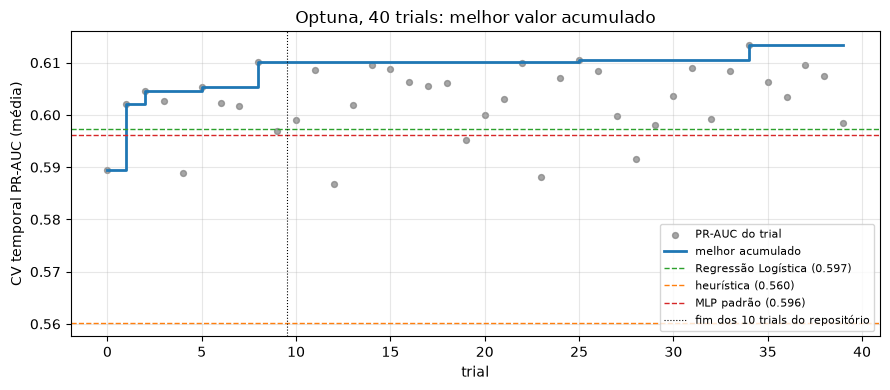

 number  value  melhor_acumulado
      0  0.589             0.589
      4  0.589             0.605
      9  0.597             0.610
     19  0.595             0.610
     29  0.598             0.610
     39  0.599             0.613
trials com PR-AUC abaixo da heurística: 0 | acima da Regressão Logística: 33


In [9]:
r_lr, r_h = resultados[(ALVO, "regressao_logistica")], resultados[(ALVO, "heuristica_recorrencia")]
r_pad = resultados[(ALVO, "mlp_padrao")]
fig, ax = plt.subplots(figsize=(9, 4))
ax.scatter(trials["number"], trials["value"], s=18, color="gray", alpha=.7, label="PR-AUC do trial")
ax.step(trials["number"], trials["melhor_acumulado"], where="post", color="C0", lw=2, label="melhor acumulado")
for r, nome, cor in [(r_lr, "Regressão Logística", "C2"), (r_h, "heurística", "C1"), (r_pad, "MLP padrão", "C3")]:
    ax.axhline(r["cv_temporal_pr_auc_mean"], ls="--", lw=1, color=cor, label=f"{nome} ({r['cv_temporal_pr_auc_mean']:.3f})")
ax.axvline(9.5, color="k", lw=.8, ls=":", label="fim dos 10 trials do repositório")
ax.set(xlabel="trial", ylabel="CV temporal PR-AUC (média)", title="Optuna, 40 trials: melhor valor acumulado")
ax.legend(fontsize=8, loc="lower right")
salvar(fig, "optuna_melhor_acumulado.png")
print(trials[["number", "value", "melhor_acumulado"]].iloc[[0, 4, 9, 19, 29, n_feitos - 1]].to_string(index=False))
print("trials com PR-AUC abaixo da heurística:", int((trials["value"] < r_h["cv_temporal_pr_auc_mean"]).sum()),
      "| acima da Regressão Logística:", int((trials["value"] > r_lr["cv_temporal_pr_auc_mean"]).sum()))

**Leitura.** A busca ganha pouco sobre o primeiro bloco de trials. O trial 0 dá 0,589. O melhor dos 10
primeiros (trial 8) já dá 0,610, e o melhor dos 40 (trial 34: `128-64`, `alpha` ≈ 0,0023,
`learning_rate_init` ≈ 0,0074) chega a 0,613. Os 30 trials depois do 10º acrescentam +0,003,
sete vezes menos que o desvio entre folds do melhor (0,022). Nenhum trial ficou abaixo da heurística
(0,560), e 33 dos 40 ficaram acima da Regressão Logística (0,597). O platô é largo: os 10 melhores
trials ficam entre 0,608 e 0,613. Nenhum dos 160 ajustes emitiu `ConvergenceWarning`. Cada trial
levou de 3 a 17 s (mediana de 7,2 s).

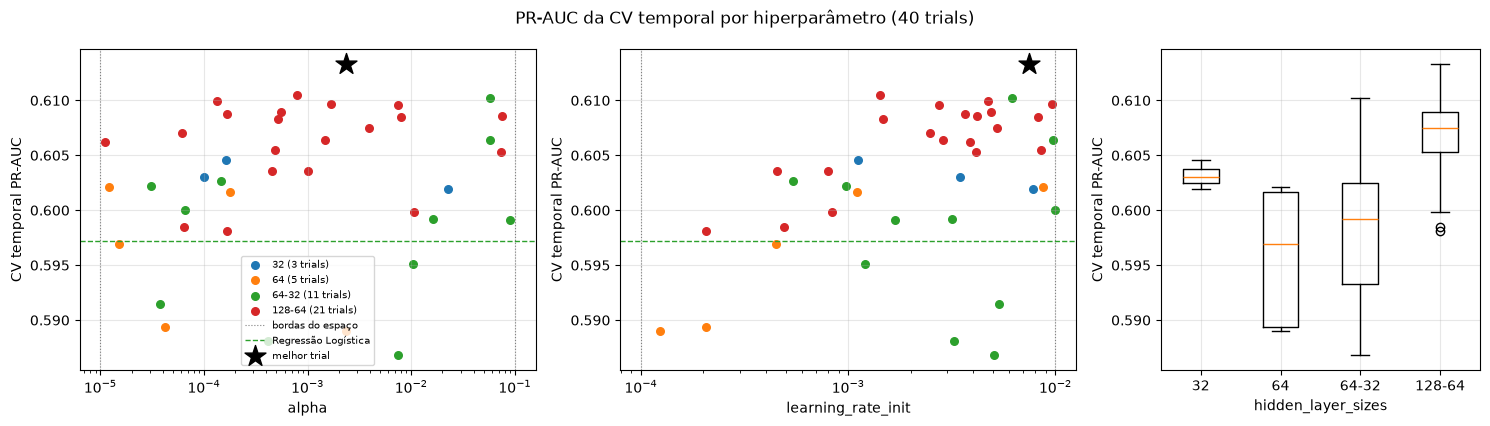

                    count   mean    max
hidden_layer_sizes                     
128-64                 21  0.607  0.613
32                      3  0.603  0.605
64                      5  0.596  0.602
64-32                  11  0.598  0.610

Spearman hiperparâmetro × PR-AUC: {'alpha': np.float64(0.192), 'learning_rate_init': np.float64(0.41)}

posição do melhor valor no espaço (escala log; 0 = borda de baixo, 1 = borda de cima):
  alpha = 0.00233: 0.59
  learning_rate_init = 0.00742: 0.94
  hidden_layer_sizes = 128-64 (opções, da menor para a maior: ['32', '64', '64-32', '128-64'])

nos 10 melhores trials:
  alpha: posição log de 0.28 a 0.97 | valores de 0.00013 a 0.074
  learning_rate_init: posição log de 0.58 a 0.99 | valores de 0.0014 a 0.0097
  arquiteturas: {'128-64': 9, '64-32': 1}


In [10]:
fig, axs = plt.subplots(1, 3, figsize=(15, 4.3), gridspec_kw={"width_ratios": [2, 2, 1.4]})
for i, a in enumerate(ARQUITETURAS):
    t = trials[trials["hidden_layer_sizes"] == a]
    for ax, hp in zip(axs[:2], ["alpha", "learning_rate_init"]):
        ax.scatter(t[hp], t["value"], color=f"C{i}", s=30, label=f"{a} ({len(t)} trials)")
for ax, hp in zip(axs[:2], ["alpha", "learning_rate_init"]):
    lo, hi = BORDAS[hp]
    ax.axvline(lo, color="gray", lw=.8, ls=":")
    ax.axvline(hi, color="gray", lw=.8, ls=":", label="bordas do espaço")
    ax.axhline(r_lr["cv_temporal_pr_auc_mean"], color="C2", ls="--", lw=1, label="Regressão Logística")
    ax.scatter([params_melhor[hp]], [melhor.value], marker="*", s=250, color="k", zorder=5, label="melhor trial")
    ax.set(xscale="log", xlabel=hp, ylabel="CV temporal PR-AUC")
axs[0].legend(fontsize=7)
presentes = [a for a in ARQUITETURAS if (trials["hidden_layer_sizes"] == a).any()]
axs[2].boxplot([trials.loc[trials["hidden_layer_sizes"] == a, "value"] for a in presentes])
axs[2].set_xticks(range(1, len(presentes) + 1), presentes)
axs[2].set(xlabel="hidden_layer_sizes", ylabel="CV temporal PR-AUC")
fig.suptitle("PR-AUC da CV temporal por hiperparâmetro (40 trials)")
salvar(fig, "optuna_pr_auc_por_hiperparametro.png")
print(trials.groupby("hidden_layer_sizes")["value"].agg(["count", "mean", "max"]).round(4).to_string())
print("\nSpearman hiperparâmetro × PR-AUC:",
      {hp: round(trials[hp].corr(trials["value"], method="spearman"), 3) for hp in BORDAS})


def posicao_log(v, lo, hi):
    return (np.log(v) - np.log(lo)) / (np.log(hi) - np.log(lo))


print("\nposição do melhor valor no espaço (escala log; 0 = borda de baixo, 1 = borda de cima):")
for hp, (lo, hi) in BORDAS.items():
    print(f"  {hp} = {params_melhor[hp]:.3g}: {posicao_log(params_melhor[hp], lo, hi):.2f}")
print(f"  hidden_layer_sizes = {melhor.params['hidden_layer_sizes']} (opções, da menor para a maior: {ARQUITETURAS})")
top10 = trials.nlargest(10, "value")
print("\nnos 10 melhores trials:")
for hp, (lo, hi) in BORDAS.items():
    pos = posicao_log(top10[hp], lo, hi)
    print(f"  {hp}: posição log de {pos.min():.2f} a {pos.max():.2f} | valores de {top10[hp].min():.2g} a {top10[hp].max():.2g}")
print("  arquiteturas:", top10["hidden_layer_sizes"].value_counts().to_dict())

**Leitura.**

- **Arquitetura:** `128-64` é a melhor em média (0,607 em 21 trials) e tem o máximo (0,613). `64-32`
  vem depois (média de 0,598 e máximo de 0,610 em 11 trials), e as camadas únicas ficam abaixo
  (`32`: 0,603; `64`: 0,596). O TPE concentrou 21 dos 40 trials em `128-64`, e 9 dos 10 melhores
  usam essa arquitetura.
- **`learning_rate_init` é o hiperparâmetro contínuo que mais pesa** (Spearman +0,41 com o PR-AUC,
  contra +0,19 do `alpha`). Os 10 melhores trials usam de 0,0014 a 0,0097.
- **`alpha` quase não importa:** os 10 melhores trials cobrem de 1,3e-4 a 7,4e-2, quase três ordens
  de grandeza, com o mesmo PR-AUC. A seção 7 mostra por quê.
- **Bordas do espaço.** O melhor `learning_rate_init` (0,0074) está a 0,94 do caminho entre 1e-4 e
  1e-2 em escala log, **colado na borda de cima**. Os 10 melhores ficam entre 0,58 e 0,99 dessa
  escala. A melhor arquitetura, `128-64`, também é a **maior opção do espaço**, ou seja, outra borda.
  O `alpha` (0,59 em escala log) fica no meio. É possível que taxas de aprendizado acima de 1e-2 ou
  redes maiores rendam um pouco mais, mas isso não foi testado: o espaço é o do repositório e não
  foi ampliado. Pelo platô dos 10 melhores (0,608 a 0,613), um ganho grande seria improvável.

### Valeu ampliar de 10 para 40 trials?

O repositório usa 10 trials (`T.N_TRIALS`, seção 17.5). Rodo um estudo separado de 10 trials, com
a mesma semente e o mesmo objetivo, para comparar com os 40. A validação de 2023 dos dois melhores
é só reportada, sem registro no MLflow.

In [11]:
estudo10, tempo10 = estudar(10)
params10 = params_do_trial(estudo10.best_params)
m10 = em_validacao(yv, montar_pipeline(features, MODELO, **params10).fit(Xtr, ytr).predict_proba(Xv)[:, 1], tri_v)
comparacao_busca = pd.DataFrame({
    "10 trials (padrão do repositório)": {"tempo (s)": tempo10, "melhor trial": estudo10.best_trial.number,
                                          "CV temporal PR-AUC": estudo10.best_value, "Val PR-AUC": m10["pr_auc"],
                                          "Val Precisão@100": m10["precisao_at_100"], "params": params10},
    "40 trials": {"tempo (s)": tempo_busca, "melhor trial": melhor.number, "CV temporal PR-AUC": melhor.value,
                  "Val PR-AUC": m_otim["pr_auc"], "Val Precisão@100": m_otim["precisao_at_100"], "params": params_melhor},
}).T
print("os 10 primeiros trials dos 40 coincidem com o estudo de 10:",
      np.allclose(trials["value"].iloc[:10], [t.value for t in estudo10.trials]))
print(f"ganho de CV temporal PR-AUC com 40 trials: {melhor.value - estudo10.best_value:+.4f} "
      f"(desvio entre folds do melhor: {extras_otim['cv_temporal_pr_auc_std']:.4f})")
comparacao_busca

os 10 primeiros trials dos 40 coincidem com o estudo de 10: True
ganho de CV temporal PR-AUC com 40 trials: +0.0031 (desvio entre folds do melhor: 0.0219)


,tempo (s),melhor trial,CV temporal PR-AUC,Val PR-AUC,Val Precisão@100,params
10 trials (padrão do repositório),56.612,8,0.61,0.66,0.905,"{'hidden_layer_sizes': [64, 32], 'alpha': 0.05..."
40 trials,296.187,34,0.613,0.651,0.898,"{'hidden_layer_sizes': [128, 64], 'alpha': 0.0..."


**Leitura: ampliar para 40 trials não valeu.** Com a mesma semente, os 10 primeiros trials dos 40
são idênticos ao estudo de 10. O estudo de 10 acha o seu melhor no trial 8 (`64-32`, `alpha` ≈ 0,057,
`learning_rate_init` ≈ 0,006, com 0,610 na CV temporal). Os 40 trials trocam para `128-64` e ganham
+0,003 na CV, sete vezes menos que o desvio entre folds (0,022). Na validação de 2023, a configuração
de 40 trials é **pior**: o PR-AUC cai de 0,660 para 0,651 e a precisão@100 de 0,905 para 0,898. O
custo foi 5 vezes maior (296 s contra 57 s). A busca inteira ficou muito abaixo do limite de 30
minutos, então não foi preciso reduzir os trials.

## 6. Diagnóstico da melhor configuração

Curva de aprendizado com `metricas.curva_aprendizado` nos 4 folds temporais (fatias de 33%, 66% e
100% do treino de cada fold), e PR-AUC no próprio treino × CV temporal × validação 2023.

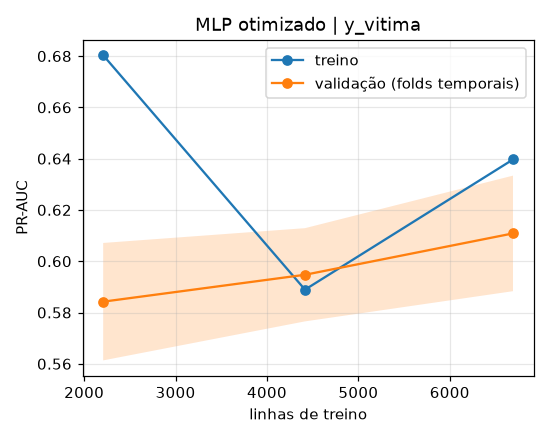

,linhas de treino,treino (média),validação dos folds (média),validação (desvio),treino − validação
0,2208,0.680,0.584,0.023,0.096
1,4416,0.589,0.595,0.018,-0.006
2,6692,0.640,0.611,0.023,0.029


In [12]:
from sklearn.model_selection import learning_curve

titulo_otim = f"MLP otimizado | {ALVO}"
metricas.curva_aprendizado(clone(pipe_otim), Xtr, ytr, folds, FIG / "curva_aprendizado.png", titulo_otim)
display(Image(FIG / "curva_aprendizado.png"))
# os mesmos números da figura, para a leitura
tam, s_tr, s_va = learning_curve(clone(pipe_otim), Xtr, ytr, cv=folds, train_sizes=[0.33, 0.66, 1.0],
                                 scoring="average_precision", n_jobs=1)
pd.DataFrame({"linhas de treino": tam, "treino (média)": s_tr.mean(1), "validação dos folds (média)": s_va.mean(1),
              "validação (desvio)": s_va.std(1), "treino − validação": s_tr.mean(1) - s_va.mean(1)}).round(3)

**Leitura da curva de aprendizado.** O PR-AUC da validação dos folds sobe com o tamanho do treino:
0,584 com 33%, 0,595 com 66% e 0,611 com 100%, e a curva ainda não achatou. Mais dados ainda devem
ajudar. O PR-AUC do treino não cai de forma monotônica (0,680, depois 0,589, depois 0,640), o que é
compatível com uma parada antecipada que decide o nº de épocas de forma irregular (ver a seção 7).
Com o treino inteiro, a distância entre treino e validação é pequena (0,029). Não há sinal de
overfitting forte.

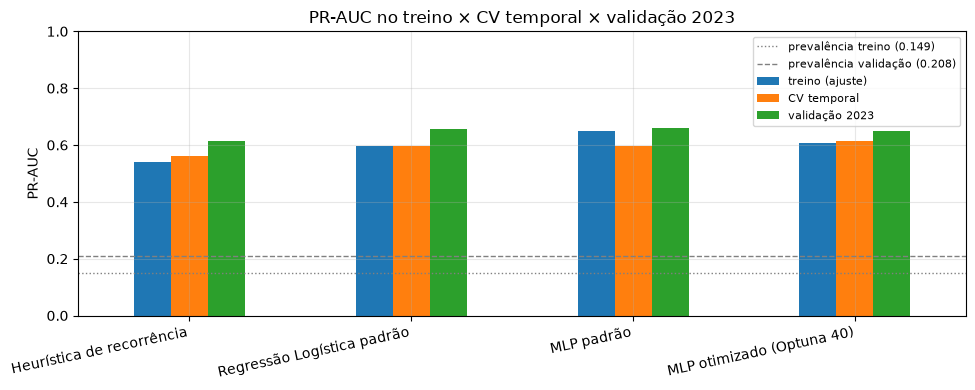

,treino (ajuste),CV temporal,validação 2023,treino − CV temporal
Heurística de recorrência,0.540,0.560,0.614,-0.020
Regressão Logística padrão,0.595,0.597,0.658,-0.002
MLP padrão,0.648,0.596,0.661,0.052
MLP otimizado (Optuna 40),0.608,0.613,0.651,-0.006


In [13]:
def treino_val(nome, pipe=None, score_fn=None):
    r = resultados[(ALVO, nome)]
    if pipe is not None:
        treino = average_precision_score(ytr, clone(pipe).fit(Xtr, ytr).predict_proba(Xtr)[:, 1])
    else:
        treino = average_precision_score(ytr, score_fn(partes["treino"]))
    return {"treino (ajuste)": treino, "CV temporal": r["cv_temporal_pr_auc_mean"], "validação 2023": r["val_pr_auc"]}


tv = pd.DataFrame({
    NOMES["heuristica_recorrencia"]: treino_val("heuristica_recorrencia", score_fn=score_heuristica),
    NOMES["regressao_logistica"]: treino_val("regressao_logistica", montar_pipeline(features, "regressao_logistica")),
    NOMES["mlp_padrao"]: treino_val("mlp_padrao", montar_pipeline(features, MODELO)),
    NOMES["mlp_otimizado"]: treino_val("mlp_otimizado", pipe_otim),
}).T
tv["treino − CV temporal"] = tv["treino (ajuste)"] - tv["CV temporal"]
fig, ax = plt.subplots(figsize=(10, 4))
tv.iloc[:, :3].plot.bar(ax=ax)
ax.axhline(ytr.mean(), color="gray", ls=":", lw=1, label=f"prevalência treino ({ytr.mean():.3f})")
ax.axhline(yv.mean(), color="gray", ls="--", lw=1, label=f"prevalência validação ({yv.mean():.3f})")
ax.set(ylabel="PR-AUC", ylim=(0, 1), title="PR-AUC no treino × CV temporal × validação 2023")
ax.legend(fontsize=8, loc="upper right")
plt.setp(ax.get_xticklabels(), rotation=12, ha="right")
salvar(fig, "pr_auc_treino_validacao.png")
tv.round(3)

**Leitura: o MLP otimizado não está em overfitting; ele está perto do nível de ajuste da Regressão
Logística.** No treino inteiro, o MLP otimizado tem PR-AUC de 0,608, que é *menor* que o da sua
própria CV temporal (0,613) e só um pouco maior que o da Regressão Logística no treino (0,595). Uma
rede `128-64` com 26 mil pesos, ajustada assim, está limitada por viés, e não por variância. O MLP
padrão se ajusta mais ao treino (0,648, +0,052 sobre a CV) e não ganha nada na CV com isso (0,596).
A validação de 2023 fica acima da CV em todos (prevalência de 0,208 contra 0,149), e é nela que o
MLP otimizado aparece abaixo da Regressão Logística (0,651 contra 0,658).

### Estabilidade: PR-AUC por fold temporal

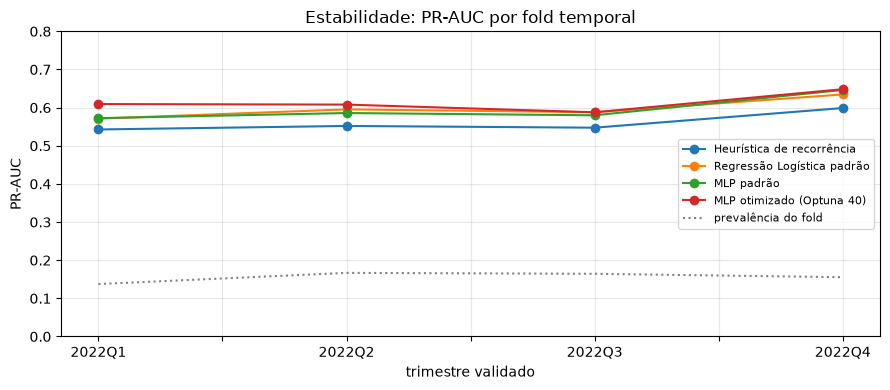

MLP otimizado − Regressão Logística, por fold: {'2022Q1': 0.0382, '2022Q2': 0.0126, '2022Q3': -0.0001, '2022Q4': 0.0138}


,Heurística de recorrência,Regressão Logística padrão,MLP padrão,MLP otimizado (Optuna 40),prevalência do fold
2022Q1,0.543,0.571,0.572,0.609,0.137
2022Q2,0.552,0.595,0.586,0.608,0.167
2022Q3,0.547,0.588,0.580,0.588,0.164
2022Q4,0.599,0.635,0.646,0.648,0.155
desvio (ddof=0),0.023,0.023,0.029,0.022,0.012


In [14]:
def por_fold(pipe=None, score=None, X=None, y=None, splits=None):
    """PR-AUC em cada fold temporal (o _cv só devolve média e desvio)."""
    X, y, splits = (Xtr, ytr, folds) if X is None else (X, y, splits)
    saida = []
    for tr, te in splits:
        s = score.iloc[te] if score is not None else clone(pipe).fit(X.iloc[tr], y.iloc[tr]).predict_proba(X.iloc[te])[:, 1]
        saida.append(average_precision_score(y.iloc[te], s))
    return saida


rotulos = [tri_tr[te][0] for _, te in folds]
folds_df = pd.DataFrame({
    NOMES["heuristica_recorrencia"]: por_fold(score=score_heuristica(partes["treino"])),
    NOMES["regressao_logistica"]: por_fold(montar_pipeline(features, "regressao_logistica")),
    NOMES["mlp_padrao"]: por_fold(montar_pipeline(features, MODELO)),
    NOMES["mlp_otimizado"]: por_fold(pipe_otim),
    "prevalência do fold": [ytr.iloc[te].mean() for _, te in folds],
}, index=rotulos)
fig, ax = plt.subplots(figsize=(9, 4))
folds_df.iloc[:, :4].plot(ax=ax, marker="o")
folds_df["prevalência do fold"].plot(ax=ax, color="gray", ls=":", label="prevalência do fold")
ax.set(xlabel="trimestre validado", ylabel="PR-AUC", ylim=(0, .8), title="Estabilidade: PR-AUC por fold temporal")
ax.legend(fontsize=8)
salvar(fig, "pr_auc_por_fold.png")
dif_fold = folds_df[NOMES["mlp_otimizado"]] - folds_df[NOMES["regressao_logistica"]]
folds_df.loc["desvio (ddof=0)"] = folds_df.std(ddof=0)
print("MLP otimizado − Regressão Logística, por fold:", dif_fold.round(4).to_dict())
folds_df.round(3)

**Leitura.** Os quatro modelos sobem e descem juntos de um fold para outro: todos têm o maior PR-AUC
em 2022Q4 e o menor em 2022Q1 ou 2022Q3. Os desvios entre folds são parecidos (0,022 a 0,029), e o
MLP otimizado tem o menor (0,022). Na comparação pareada, fold a fold, o MLP otimizado nunca perde da
Regressão Logística: +0,038 em 2022Q1, +0,013 em 2022Q2, 0,000 em 2022Q3 e +0,014 em 2022Q4. O
sinal é consistente, mas a vantagem média (+0,016) é menor que o desvio entre folds, e mais da
metade dela vem de um único fold (2022Q1).

### Sensibilidade à semente

O `random_state` do MLP controla três coisas: a inicialização dos pesos, a ordem dos mini-lotes e
o sorteio dos 10% da validação interna do `early_stopping`. Treino a melhor configuração com 5
sementes (42, 0, 1, 2, 3), sem registrar runs, e meço o PR-AUC na CV temporal e na validação. O
desvio entre sementes é o desvio amostral (ddof=1). A Regressão Logística (lbfgs) e a heurística
são determinísticas.

5 sementes em 54.1 s


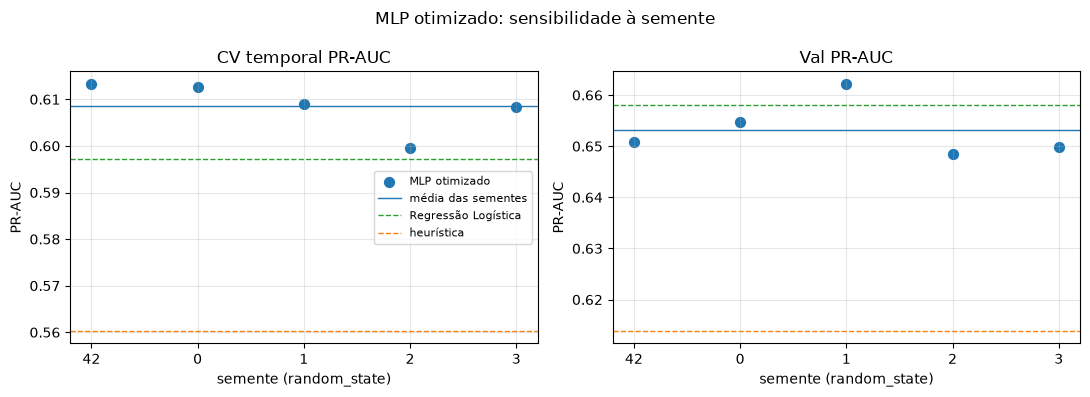

,CV temporal PR-AUC,desvio entre folds,Val PR-AUC,Val Precisão@100,épocas (treino inteiro)
semente,,,,,
42,0.613,0.022,0.651,0.897,12
0,0.613,0.023,0.655,0.900,14
1,0.609,0.026,0.662,0.900,16
2,0.600,0.044,0.648,0.907,17
3,0.608,0.029,0.650,0.892,17


,CV temporal,validação 2023
MLP otimizado (média das 5 sementes),0.609,0.653
desvio entre sementes (ddof=1),0.005,0.005
amplitude entre sementes (máx − mín),0.014,0.014
Regressão Logística,0.597,0.658
MLP − Regressão Logística,0.011,-0.005
heurística,0.560,0.614
MLP − heurística,0.048,0.039
"desvio entre folds (CV, semente 42)",0.022,NaN


In [15]:
SEMENTES = [42, 0, 1, 2, 3]
linhas_s = []
t0 = time.time()
for s in SEMENTES:
    p = montar_pipeline(features, MODELO, **params_melhor, random_state=s)
    cv = _cv(p, Xtr, ytr, folds)
    ajustado = clone(p).fit(Xtr, ytr)
    sv = ajustado.predict_proba(Xv)[:, 1]
    linhas_s.append({"semente": s, "CV temporal PR-AUC": cv["cv_temporal_pr_auc_mean"],
                     "desvio entre folds": cv["cv_temporal_pr_auc_std"], "Val PR-AUC": average_precision_score(yv, sv),
                     "Val Precisão@100": metricas.no_topo(yv, sv, tri_v, 100)[1],
                     "épocas (treino inteiro)": ajustado.named_steps["modelo"].n_iter_})
sementes = pd.DataFrame(linhas_s).set_index("semente")
print(f"5 sementes em {time.time() - t0:.1f} s")
resumo_s = sementes.agg(["mean", "std"])
sens = pd.DataFrame({
    parte: {"MLP otimizado (média das 5 sementes)": resumo_s.loc["mean", col],
            "desvio entre sementes (ddof=1)": resumo_s.loc["std", col],
            "amplitude entre sementes (máx − mín)": sementes[col].max() - sementes[col].min(),
            "Regressão Logística": r_lr[chave], "MLP − Regressão Logística": resumo_s.loc["mean", col] - r_lr[chave],
            "heurística": r_h[chave], "MLP − heurística": resumo_s.loc["mean", col] - r_h[chave]}
    for parte, col, chave in [("CV temporal", "CV temporal PR-AUC", "cv_temporal_pr_auc_mean"),
                              ("validação 2023", "Val PR-AUC", "val_pr_auc")]})
sens.loc["desvio entre folds (CV, semente 42)"] = [extras_otim["cv_temporal_pr_auc_std"], np.nan]

fig, axs = plt.subplots(1, 2, figsize=(11, 4))
for ax, col, chave in [(axs[0], "CV temporal PR-AUC", "cv_temporal_pr_auc_mean"), (axs[1], "Val PR-AUC", "val_pr_auc")]:
    ax.scatter(range(len(SEMENTES)), sementes[col], s=50, color="C0", label="MLP otimizado")
    ax.axhline(sementes[col].mean(), color="C0", lw=1, label="média das sementes")
    ax.axhline(r_lr[chave], color="C2", ls="--", lw=1, label="Regressão Logística")
    ax.axhline(r_h[chave], color="C1", ls="--", lw=1, label="heurística")
    ax.set_xticks(range(len(SEMENTES)), [str(s) for s in SEMENTES])
    ax.set(xlabel="semente (random_state)", ylabel="PR-AUC", title=col)
axs[0].legend(fontsize=8)
fig.suptitle("MLP otimizado: sensibilidade à semente")
salvar(fig, "sensibilidade_semente.png")
display(sementes.round(4))
sens.round(4)

**Leitura: o ganho sobre a Regressão Logística não é conclusivo.**

- Com 5 sementes, o MLP otimizado tem PR-AUC de 0,609 ± 0,005 na CV temporal (de 0,600 a 0,613) e de
  0,653 ± 0,005 na validação de 2023 (de 0,648 a 0,662).
- A semente 42, usada na busca, é a melhor das cinco na CV (0,613). Parte do valor do melhor trial é
  sorte da semente: o Optuna escolheu a configuração que, *com essa semente*, deu o maior número. Na
  média das sementes, a vantagem sobre a Regressão Logística na CV cai de +0,016 para +0,011.
- **Na CV temporal**, a diferença para a Regressão Logística (+0,011) é maior que o desvio entre
  sementes (0,005), mas é a metade do desvio entre folds (0,022). **Na validação de 2023**, ela é
  negativa (−0,005) e do tamanho do desvio entre sementes. Nenhuma das duas sustenta que o MLP seja
  melhor que a Regressão Logística.
- **Contra a heurística**, a vantagem é clara: +0,048 na CV e +0,039 na validação, de 8 a 10 vezes o
  desvio entre sementes e cerca de 2 vezes o desvio entre folds.
- A semente também muda a estabilidade entre folds: o desvio entre folds vai de 0,022 (semente 42) a
  0,044 (semente 2).

## 7. Análise própria do MLP

### Curva de perda e parada antecipada

`loss_curve_` é a perda de entropia cruzada (com o termo L2) no treino, por época, e
`validation_scores_` é a acurácia na validação interna de 10% que o `early_stopping` usa. Os dois
são do ajuste do run da melhor configuração (treino inteiro, semente 42).

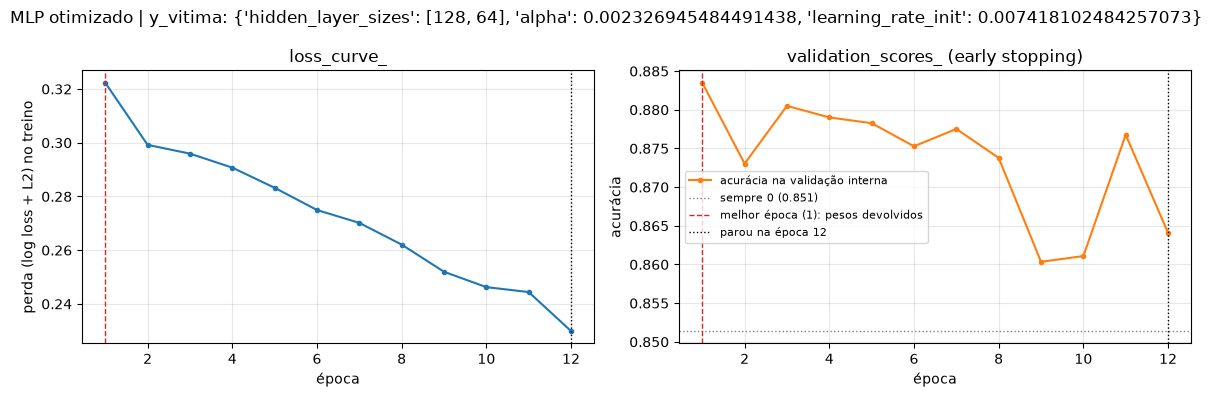

épocas: 12 | melhor época interna: 1 | perda: época 1 0.3223, melhor época 0.3223, última 0.2299
acurácia interna: época 1 0.8835 | máx 0.8835 | última 0.8641 | valores distintos: 12
validação interna: 1339 linhas (10% do treino)


In [16]:
mlp_otim = pipe_otim.named_steps["modelo"]
epocas = np.arange(1, mlp_otim.n_iter_ + 1)
melhor_epoca = int(np.argmax(mlp_otim.validation_scores_)) + 1
fig, axs = plt.subplots(1, 2, figsize=(12, 4))
axs[0].plot(epocas, mlp_otim.loss_curve_, marker=".")
axs[0].set(xlabel="época", ylabel="perda (log loss + L2) no treino", title="loss_curve_")
axs[1].plot(epocas, mlp_otim.validation_scores_, marker=".", color="C1", label="acurácia na validação interna")
axs[1].axhline(1 - ytr.mean(), color="gray", ls=":", lw=1, label=f"sempre 0 ({1 - ytr.mean():.3f})")
for ax in axs:
    ax.axvline(melhor_epoca, color="C3", ls="--", lw=1, label=f"melhor época ({melhor_epoca}): pesos devolvidos")
    ax.axvline(mlp_otim.n_iter_, color="k", ls=":", lw=1, label=f"parou na época {mlp_otim.n_iter_}")
axs[1].set(xlabel="época", ylabel="acurácia", title="validation_scores_ (early stopping)")
axs[1].legend(fontsize=8)
fig.suptitle(f"{titulo_otim}: {params_melhor}")
salvar(fig, "curva_perda_early_stopping.png")
print(f"épocas: {mlp_otim.n_iter_} | melhor época interna: {melhor_epoca} | "
      f"perda: época 1 {mlp_otim.loss_curve_[0]:.4f}, melhor época {mlp_otim.loss_curve_[melhor_epoca - 1]:.4f}, "
      f"última {mlp_otim.loss_curve_[-1]:.4f}")
print(f"acurácia interna: época 1 {mlp_otim.validation_scores_[0]:.4f} | máx {max(mlp_otim.validation_scores_):.4f} | "
      f"última {mlp_otim.validation_scores_[-1]:.4f} | valores distintos: {len(set(np.round(mlp_otim.validation_scores_, 6)))}")
print("validação interna:", int(np.ceil(0.1 * len(Xtr))), "linhas (10% do treino)")

**Leitura: o modelo devolvido é o da 1ª época.** A perda no treino cai de forma contínua, de 0,322
na época 1 para 0,230 na época 12. Já a acurácia na validação interna (1.339 linhas sorteadas do
treino) é máxima logo na época 1 (0,8835) e depois só cai, até 0,864. O `early_stopping` espera 10
épocas sem melhora, para na 12ª e devolve os pesos da 1ª. A curva mostra o padrão clássico de
overfitting a partir da 2ª época: o treino melhora e a validação interna piora. Mas a parada
escolhe um modelo que viu os dados **uma única vez**, com uma taxa de aprendizado alta (0,0074).
Isso explica por que o MLP otimizado se ajusta ao treino quase tanto quanto a Regressão Logística
(seção 6). O critério da parada é a acurácia, que só tem 12 valores distintos ao longo das épocas
e fica pouco acima dos 0,851 de "sempre 0". É uma medida grosseira para um modelo que será usado
para ranquear.

### Efeito da regularização (`alpha`) e da arquitetura

Cada varredura muda um hiperparâmetro e deixa o resto fixo na melhor configuração. Para cada ponto:
PR-AUC da CV temporal (média ± desvio entre folds), PR-AUC no próprio treino (ajuste no treino
inteiro), PR-AUC na validação de 2023 e épocas até parar. A distância treino − CV temporal indica
variância (overfitting), e o nível da CV temporal indica viés.

varredura de alpha em 52.7 s


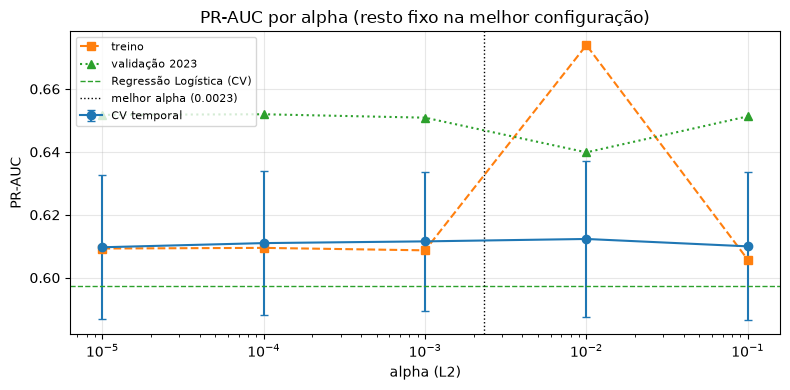

,CV temporal PR-AUC,desvio entre folds,treino PR-AUC,Val PR-AUC,épocas,treino − CV
alpha,,,,,,
1.000e-05,0.610,0.023,0.609,0.652,12,-4.000e-04
1.000e-04,0.611,0.023,0.610,0.652,12,-1.500e-03
1.000e-03,0.612,0.022,0.609,0.651,12,-2.900e-03
1.000e-02,0.612,0.025,0.674,0.640,18,6.160e-02
1.000e-01,0.610,0.024,0.606,0.651,12,-4.200e-03


In [17]:
def varrer(**mudanca):
    p = montar_pipeline(features, MODELO, **{**params_melhor, **mudanca})
    cv = _cv(p, Xtr, ytr, folds)
    aj = clone(p).fit(Xtr, ytr)
    return {"CV temporal PR-AUC": cv["cv_temporal_pr_auc_mean"], "desvio entre folds": cv["cv_temporal_pr_auc_std"],
            "treino PR-AUC": average_precision_score(ytr, aj.predict_proba(Xtr)[:, 1]),
            "Val PR-AUC": average_precision_score(yv, aj.predict_proba(Xv)[:, 1]),
            "épocas": aj.named_steps["modelo"].n_iter_}


def grafico_varredura(ax, x, df, xlabel):
    ax.errorbar(x, df["CV temporal PR-AUC"], yerr=df["desvio entre folds"], marker="o", capsize=3, label="CV temporal")
    ax.plot(x, df["treino PR-AUC"], "s--", label="treino")
    ax.plot(x, df["Val PR-AUC"], "^:", label="validação 2023")
    ax.axhline(r_lr["cv_temporal_pr_auc_mean"], color="C2", ls="--", lw=1, label="Regressão Logística (CV)")
    ax.set(xlabel=xlabel, ylabel="PR-AUC")


ALPHAS = [1e-5, 1e-4, 1e-3, 1e-2, 1e-1]
t0 = time.time()
var_alpha = pd.DataFrame([{"alpha": a, **varrer(alpha=a)} for a in ALPHAS]).set_index("alpha")
var_alpha["treino − CV"] = var_alpha["treino PR-AUC"] - var_alpha["CV temporal PR-AUC"]
print(f"varredura de alpha em {time.time() - t0:.1f} s")
fig, ax = plt.subplots(figsize=(8, 4))
grafico_varredura(ax, ALPHAS, var_alpha, "alpha (L2)")
ax.axvline(params_melhor["alpha"], color="k", ls=":", lw=1, label=f"melhor alpha ({params_melhor['alpha']:.2g})")
ax.set(xscale="log", title="PR-AUC por alpha (resto fixo na melhor configuração)")
ax.legend(fontsize=8)
salvar(fig, "pr_auc_por_alpha.png")
var_alpha.round(4)

**Leitura (viés × variância).** O `alpha` quase não muda nada: o PR-AUC da CV temporal fica entre
0,610 e 0,612 de 1e-5 a 1e-1, uma faixa 10 vezes menor que o desvio entre folds. O motivo está na
seção anterior: com quatro dos cinco valores de `alpha`, o ajuste para na 12ª época e devolve a 1ª,
e a penalidade L2 não tem tempo de agir. Quem regulariza este modelo é a parada antecipada, não o
`alpha`. A exceção é `alpha=1e-2`, em que o ajuste no treino inteiro foi até a 18ª época: o PR-AUC
do treino sobe para 0,674 (+0,062 sobre a CV) e o da validação de 2023 cai para 0,640, o menor da
varredura. Esse é o lado da variância: mais épocas significam mais ajuste ao treino e pior
generalização. O lado do viés não aparece no espaço testado: nem `alpha=1e-1` derruba a CV.

varredura de arquitetura em 25.4 s


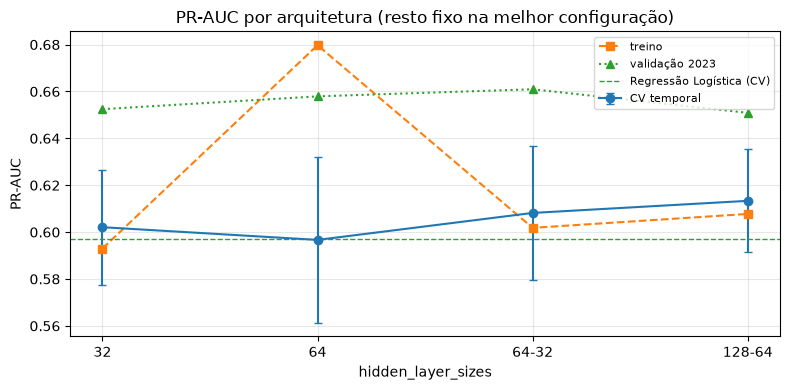

,CV temporal PR-AUC,desvio entre folds,treino PR-AUC,Val PR-AUC,épocas,treino − CV,parâmetros (pesos)
hidden_layer_sizes,,,,,,,
32,0.602,0.025,0.593,0.652,12,-0.009,4609
64,0.597,0.035,0.680,0.658,21,0.083,9217
64-32,0.608,0.029,0.602,0.661,12,-0.006,11265
128-64,0.613,0.022,0.608,0.651,12,-0.006,26625


In [18]:
t0 = time.time()
var_arq = pd.DataFrame([{"hidden_layer_sizes": a, **varrer(hidden_layer_sizes=[int(n) for n in a.split("-")])}
                        for a in ARQUITETURAS]).set_index("hidden_layer_sizes")
var_arq["treino − CV"] = var_arq["treino PR-AUC"] - var_arq["CV temporal PR-AUC"]
var_arq["parâmetros (pesos)"] = [
    sum(i * o + o for i, o in zip([N_ENTRADAS] + [int(n) for n in a.split("-")], [int(n) for n in a.split("-")] + [1]))
    for a in ARQUITETURAS]
print(f"varredura de arquitetura em {time.time() - t0:.1f} s")
fig, ax = plt.subplots(figsize=(8, 4))
grafico_varredura(ax, range(len(ARQUITETURAS)), var_arq, "hidden_layer_sizes")
ax.set_xticks(range(len(ARQUITETURAS)), ARQUITETURAS)
ax.set(title="PR-AUC por arquitetura (resto fixo na melhor configuração)")
ax.legend(fontsize=8)
salvar(fig, "pr_auc_por_arquitetura.png")
var_arq.round(4)

**Leitura.** Com o resto fixo, a CV temporal vai de 0,597 (`64`) a 0,613 (`128-64`): `32` (0,602),
`64-32` (0,608) e `128-64` passam da Regressão Logística (0,597), e `64` empata com ela. As diferenças entre as arquiteturas
(até 0,016) são menores que o desvio entre folds (0,022 a 0,035). Na validação de 2023, a ordem
quase se inverte: `64-32` (0,661) e `64` (0,658) ficam acima de `128-64` (0,651). Outra vez, o
número de épocas explica o ajuste ao treino. `64` treinou 21 épocas, tem o maior PR-AUC no treino
(0,680, +0,083 sobre a CV) e o maior desvio entre folds (0,035). As outras pararam na 12ª e ficam
com o treino no nível da CV. Multiplicar os pesos por 6 (de 4.609 em `32` para 26.625 em `128-64`)
rende +0,011 na CV e nada na validação.

### Custo: tempo de ajuste e de predição

Mediana de 3 repetições, ajuste no treino inteiro (13.384 linhas) e predição na validação (6.692).

In [19]:
def cronometrar(pipe, Xa, ya, Xp, rep=3):
    tf, tp = [], []
    for _ in range(rep):
        p = clone(pipe)
        t0 = time.perf_counter(); p.fit(Xa, ya); tf.append(time.perf_counter() - t0)
        t0 = time.perf_counter(); p.predict_proba(Xp); tp.append(time.perf_counter() - t0)
    return float(np.median(tf)), float(np.median(tp))


custo = {}
for nome, pipe in [(NOMES["regressao_logistica"], montar_pipeline(features, "regressao_logistica")),
                   (NOMES["mlp_padrao"], montar_pipeline(features, MODELO)),
                   (NOMES["mlp_otimizado"], pipe_otim)]:
    tf, tp = cronometrar(pipe, Xtr, ytr, Xv)
    custo[nome] = {"ajuste (s)": tf, "predição na validação (s)": tp}
custo = pd.DataFrame(custo).T
custo["ajuste ÷ Regressão Logística"] = custo["ajuste (s)"] / custo.loc[NOMES["regressao_logistica"], "ajuste (s)"]
custo["predição ÷ Regressão Logística"] = (custo["predição na validação (s)"]
                                            / custo.loc[NOMES["regressao_logistica"], "predição na validação (s)"])
custo.round(3)

,ajuste (s),predição na validação (s),ajuste ÷ Regressão Logística,predição ÷ Regressão Logística
Regressão Logística padrão,2.421,0.075,1.000,1.000
MLP padrão,2.438,0.041,1.007,0.543
MLP otimizado (Optuna 40),2.476,0.069,1.023,0.924


**Leitura.** Com a parada antecipada em 12 a 21 épocas, o MLP custa o mesmo que a Regressão
Logística: cerca de 2,4 a 2,5 s de ajuste no treino inteiro (o MLP otimizado leva 1,02 vez o tempo da
Regressão Logística), e a predição das 6.692 linhas leva menos de 0,1 s nos três. O custo do MLP
está na busca: 40 trials levaram 4,9 min, e as 5 sementes mais as varreduras de `alpha` e de
arquitetura, cerca de 2 min.

### Importância por permutação na validação de 2023

`metricas.importancia_permutacao` (queda média de PR-AUC ao embaralhar cada coluna original, antes
do one-hot, 5 repetições, semente 42), sobre o MLP otimizado ajustado no treino.

tempo da permutação: 12.3 s (48 colunas × 5 repetições)


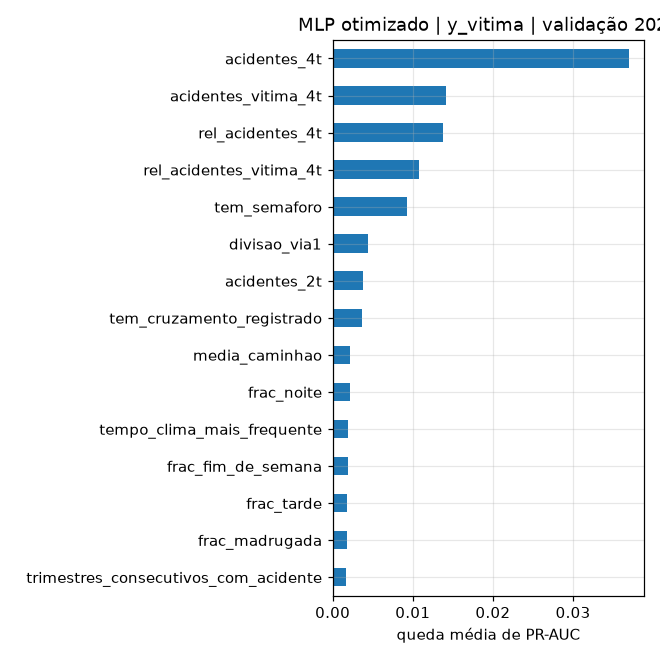

atributos com queda de PR-AUC > 0: 38 de 48 | com queda < 0: 9
soma das quedas das 15 primeiras: 0.1101 | da 1ª: 0.0369


,queda média de PR-AUC
acidentes_4t,0.037
acidentes_vitima_4t,0.014
rel_acidentes_4t,0.014
rel_acidentes_vitima_4t,0.011
tem_semaforo,0.009
divisao_via1,0.004
acidentes_2t,0.004
tem_cruzamento_registrado,0.004
media_caminhao,0.002
frac_noite,0.002


In [20]:
t0 = time.time()
_, imp_perm = metricas.importancia_permutacao(pipe_otim, Xv, yv, FIG / "permutation_importance.png",
                                              f"{titulo_otim} | validação 2023", top=15)
print(f"tempo da permutação: {time.time() - t0:.1f} s ({Xv.shape[1]} colunas × 5 repetições)")
display(Image(FIG / "permutation_importance.png"))
print(f"atributos com queda de PR-AUC > 0: {(imp_perm > 0).sum()} de {len(imp_perm)} | com queda < 0: {(imp_perm < 0).sum()}")
print(f"soma das quedas das 15 primeiras: {imp_perm.head(15).sum():.4f} | da 1ª: {imp_perm.iloc[0]:.4f}")
imp_perm.head(15).round(4).to_frame("queda média de PR-AUC")

**Leitura.** O MLP depende sobretudo da recorrência. As quatro primeiras colunas são o histórico de
4 trimestres do local: `acidentes_4t` (queda de 0,037), `acidentes_vitima_4t` (0,014) e as duas
versões relativas (0,014 e 0,011). Juntas, elas somam 0,076 das 0,110 de queda das 15 primeiras.
Depois vêm `tem_semaforo` (0,009) e, com 0,004 ou menos cada, a divisão da via, os acidentes dos
últimos 2 trimestres e o cruzamento registrado. É a mesma informação que a heurística usa, o que
ajuda a explicar por que a vantagem do MLP sobre ela é moderada. Das 48 colunas, 38 têm queda
positiva e 9 têm queda negativa (ruído: embaralhá-las melhora um pouco o PR-AUC).

## 8. Erros na validação de 2023

Os 10 maiores falsos positivos (locais sem acidente com vítima no trimestre seguinte, com o maior
score) e os 10 maiores falsos negativos (locais com acidente, com o menor score) do MLP otimizado,
com o nome legível do local (`dim_local`). `trimestre` é o trimestre da linha (das features) e
`trimestre_alvo` é o seguinte, em que o acidente aconteceu ou não.

In [21]:
from src.comum.db import engine

dim = pd.read_sql_table("dim_local", engine())[["local_id", "bairro", "logradouro"]]
erros = (partes["validacao"][["local_id", "trimestre", "acidentes_vitima_4t", "acidentes_4t", ALVO]]
         .assign(score=score_otim).merge(dim, on="local_id", how="left"))
erros["trimestre_alvo"] = (pd.PeriodIndex(erros["trimestre"], freq="Q") + 1).astype(str)
colunas = ["bairro", "logradouro", "trimestre", "trimestre_alvo", "score", "acidentes_vitima_4t", "acidentes_4t"]
fp = erros[erros[ALVO] == 0].sort_values("score", ascending=False, kind="stable")
fn = erros[erros[ALVO] == 1].sort_values("score", kind="stable")
print(f"limiar (F1 na validação): {m_otim['limiar']:.4f} | FP: {int(m_otim['fp'])} | FN: {int(m_otim['fn'])}")
print("\n10 maiores falsos positivos")
display(fp[colunas].head(10).reset_index(drop=True))
print("10 maiores falsos negativos")
display(fn[colunas].head(10).reset_index(drop=True))
print("histórico médio (acidentes_vitima_4t) | todos os negativos:",
      round(erros.loc[erros[ALVO] == 0, "acidentes_vitima_4t"].mean(), 2),
      "| todos os positivos:", round(erros.loc[erros[ALVO] == 1, "acidentes_vitima_4t"].mean(), 2),
      "| 10 maiores FP:", round(fp["acidentes_vitima_4t"].head(10).mean(), 2),
      "| 10 maiores FN:", round(fn["acidentes_vitima_4t"].head(10).mean(), 2))
print("positivos com acidentes_4t == 0:", int(((erros[ALVO] == 1) & (erros["acidentes_4t"] == 0)).sum()),
      "de", int(erros[ALVO].sum()))
print("locais distintos entre os 10 maiores FP:", fp["local_id"].head(10).nunique(),
      "| entre os 10 maiores FN:", fn["local_id"].head(10).nunique())

limiar (F1 na validação): 0.1376 | FP: 643 | FN: 558

10 maiores falsos positivos


,bairro,logradouro,trimestre,trimestre_alvo,score,acidentes_vitima_4t,acidentes_4t
0,ENCRUZILHADA,AV NORTE MIGUEL ARRAES DE ALENCAR,2023Q1,2023Q2,0.893,10,10
1,BOA VISTA,AV GOVERNADOR AGAMENON MAGALHAES,2023Q1,2023Q2,0.828,10,15
2,MANGABEIRA,AV NORTE MIGUEL ARRAES DE ALENCAR,2023Q4,2024Q1,0.810,7,8
3,CAMPO GRANDE,RUA ODORICO MENDES,2023Q3,2023Q4,0.806,16,16
4,TEJIPIÓ,AV DR JOSE RUFINO,2023Q2,2023Q3,0.792,12,14
5,BOA VIAGEM,RUA ANTONIO FALCAO,2023Q4,2024Q1,0.771,7,7
6,BOA VIAGEM,RUA BARAO DE SOUZA LEAO,2023Q1,2023Q2,0.762,6,8
7,DOIS IRMÃOS,RUA MANUEL DE MEDEIROS,2023Q4,2024Q1,0.751,18,18
8,BOA VIAGEM,RUA RIBEIRO DE BRITO,2023Q1,2023Q2,0.742,10,12
9,VÁRZEA,AV AFONSO OLINDENSE,2023Q1,2023Q2,0.713,6,8


10 maiores falsos negativos


,bairro,logradouro,trimestre,trimestre_alvo,score,acidentes_vitima_4t,acidentes_4t
0,IPUTINGA,RUA PADRE FERNAO CARDIM,2023Q3,2023Q4,0.003,0,0
1,SÃO JOSÉ,RUA DR JOSE MARIANO,2023Q3,2023Q4,0.003,0,0
2,SÃO JOSÉ,RUA DO FORTE,2023Q1,2023Q2,0.004,0,0
3,BRASÍLIA TEIMOSA,RUA FRANCISCO VALPASSOS,2023Q2,2023Q3,0.004,0,0
4,CORDEIRO,RUA VISCONDE DE ITABORAI,2023Q3,2023Q4,0.005,0,0
5,SANTO AMARO,RUA GERVASIO PIRES,2023Q4,2024Q1,0.005,0,0
6,SÃO JOSÉ,RUA VELHA,2023Q4,2024Q1,0.007,0,0
7,JOANA BEZERRA,AV SUL,2023Q1,2023Q2,0.007,0,0
8,SOLEDADE,RUA DO PRINCIPE,2023Q2,2023Q3,0.007,0,0
9,SANTO ANTÔNIO,RUA DA PALMA,2023Q3,2023Q4,0.007,0,0


histórico médio (acidentes_vitima_4t) | todos os negativos: 0.47 | todos os positivos: 4.83 | 10 maiores FP: 10.2 | 10 maiores FN: 0.0
positivos com acidentes_4t == 0: 315 de 1392
locais distintos entre os 10 maiores FP: 10 | entre os 10 maiores FN: 10


**Leitura.** Os erros seguem o histórico do local.

- **Os 10 maiores falsos positivos** são vias com muito acidente com vítima nos 4 trimestres
  anteriores (10,2 em média, contra 4,83 de todos os positivos), como a Av. Norte Miguel Arraes de
  Alencar (Encruzilhada e Mangabeira) e a Av. Agamenon Magalhães (Boa Vista). O modelo os põe no
  topo, com score de 0,71 a 0,89, e naquele trimestre eles não tiveram acidente com vítima.
- **Os 10 maiores falsos negativos** têm histórico zero (nenhum acidente nos 4 trimestres
  anteriores), e muitos ficam em ruas do centro (São José, Santo Antônio, Santo Amaro). Nenhum
  modelo baseado em recorrência os encontra. Na validação, 315 dos 1.392 positivos (23%) vêm de
  linhas com `acidentes_4t == 0`.
- Os 10 maiores erros de cada lado são de 10 locais distintos: não é um único local que se repete.

## 9. Alvo secundário: `y_atropelamento`

A melhor configuração de `y_vitima` (sem nova busca) reavaliada em `y_atropelamento`, com as
mesmas partes e os mesmos folds, ao lado dos pisos e do MLP padrão. Só o otimizado vira run
(`busca=optuna_40`, alvo `y_atropelamento`).

**Ressalva (`ARCHITECTURE.md`, 17.2):** o atropelamento tem poucos positivos (313 no treino inteiro,
42 a 48 por fold e cerca de 38 por trimestre em 2023), para 142 colunas depois do one-hot. Com
tão poucos positivos por trimestre, o PR-AUC oscila muito de um fold para outro, e as diferenças
entre modelos têm de ser lidas contra esse desvio. Aqui o teto do Recall@50 é 1, mas o teto da
precisão@50 é baixo: com menos de 50 positivos por trimestre, nem um ranking perfeito acerta 50.

In [22]:
ALVO2 = "y_atropelamento"
partes2, folds2 = preparar(ALVO2)
Xtr2, ytr2 = _xy(partes2["treino"], ALVO2)
Xv2, yv2 = _xy(partes2["validacao"], ALVO2)
tri2, tri_v2 = partes2["treino"]["trimestre"].to_numpy(), partes2["validacao"]["trimestre"]
print(f"positivos: treino {ytr2.sum()} ({ytr2.mean():.4f}) | validação {yv2.sum()} ({yv2.mean():.4f})")
print("positivos na validação de cada fold:", {tri2[te][0]: int(ytr2.iloc[te].sum()) for _, te in folds2})
pos2 = partes2["validacao"].groupby("trimestre")[ALVO2].sum()
print("positivos por trimestre na validação 2023:", pos2.astype(int).to_dict())
for k in metricas.KS:
    TETO[(ALVO2, k)] = teto_recall(yv2, tri_v2, k)
    print(f"k={k}: teto do Recall@k {TETO[(ALVO2, k)]:.3f} | teto da precisão@k {float((np.minimum(k, pos2) / k).mean()):.3f}")

for nome, r in pisos(ALVO2, partes2, folds2).items():
    resultados[(ALVO2, nome)] = r
pad2 = montar_pipeline(features, MODELO)
cv_pad2 = {**_cv(pad2, Xtr2, ytr2, folds2), **_cv_estratificado(pad2, Xtr2, ytr2)}
resultados[(ALVO2, "mlp_padrao")] = linha(cv_pad2, em_validacao(yv2, clone(pad2).fit(Xtr2, ytr2).predict_proba(Xv2)[:, 1], tri_v2))

pipe_otim2 = montar_pipeline(features, MODELO, **params_melhor)
cv_otim2 = {**_cv(pipe_otim2, Xtr2, ytr2, folds2), **_cv_estratificado(pipe_otim2, Xtr2, ytr2)}
(run_otim2, m_otim2), avisos2 = com_avisos(_rodar, f"{MODELO}_optuna40_melhor", ALVO2, pipe_otim2, partes2, params_melhor,
                                           cv_otim2, {"etapa": "otimizacao", "busca": "optuna_40", **TAGS}, folds2)
resultados[(ALVO2, "mlp_otimizado")] = linha(cv_otim2, m_otim2, run_otim2)
print("run", run_otim2, "| ConvergenceWarning:", avisos2, "| épocas:", pipe_otim2.named_steps["modelo"].n_iter_)
folds2_df = pd.DataFrame({
    NOMES["heuristica_recorrencia"]: por_fold(score=score_heuristica(partes2["treino"]), X=Xtr2, y=ytr2, splits=folds2),
    NOMES["regressao_logistica"]: por_fold(montar_pipeline(features, "regressao_logistica"), X=Xtr2, y=ytr2, splits=folds2),
    NOMES["mlp_otimizado"]: por_fold(pipe_otim2, X=Xtr2, y=ytr2, splits=folds2),
}, index=[tri2[te][0] for _, te in folds2])
print("\nPR-AUC por fold temporal (y_atropelamento):")
display(folds2_df.round(3))
tabela(ALVO2, ["heuristica_recorrencia", "regressao_logistica", "mlp_padrao", "mlp_otimizado"])

positivos: treino 313 (0.0234) | validação 151 (0.0226)
positivos na validação de cada fold: {'2022Q1': 46, '2022Q2': 48, '2022Q3': 44, '2022Q4': 42}
positivos por trimestre na validação 2023: {'2023Q1': 40, '2023Q2': 40, '2023Q3': 36, '2023Q4': 35}
k=50: teto do Recall@k 1.000 | teto da precisão@k 0.755
k=100: teto do Recall@k 1.000 | teto da precisão@k 0.378


2026/11/23 15:32:32 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


🏃 View run mlp_optuna40_melhor at: http://mlflow:5000/#/experiments/2/runs/bc9b9241fa10438aaf63ccca614d1364
🧪 View experiment at: http://mlflow:5000/#/experiments/2
run bc9b9241fa10438aaf63ccca614d1364 | ConvergenceWarning: 0 | épocas: 13



PR-AUC por fold temporal (y_atropelamento):


,Heurística de recorrência,Regressão Logística padrão,MLP otimizado (Optuna 40)
2022Q1,0.341,0.292,0.084
2022Q2,0.296,0.302,0.258
2022Q3,0.316,0.286,0.250
2022Q4,0.318,0.332,0.330


,CV temporal PR-AUC,CV temporal ROC-AUC,CV estratificado PR-AUC,Δ PR-AUC estrat. − temporal,Val PR-AUC,Val Recall@50,Val Recall@100,Val Precisão@50,Val Precisão@100,Val ROC-AUC
Heurística de recorrência,0.318 ± 0.016,0.841 ± 0.023,0.272 ± 0.050,-0.046,0.290,0.424,0.562,0.320,0.212,0.828
Regressão Logística padrão,0.303 ± 0.018,0.818 ± 0.013,0.274 ± 0.064,-0.029,0.278,0.418,0.558,0.315,0.210,0.823
MLP padrão,0.270 ± 0.035,0.848 ± 0.016,0.255 ± 0.048,-0.015,0.279,0.459,0.597,0.345,0.225,0.848
MLP otimizado (Optuna 40),0.230 ± 0.090,0.780 ± 0.060,0.282 ± 0.046,+0.052,0.262,0.401,0.539,0.300,0.203,0.843
teto do Recall@k (validação),,,,,,1.000,1.000,,,


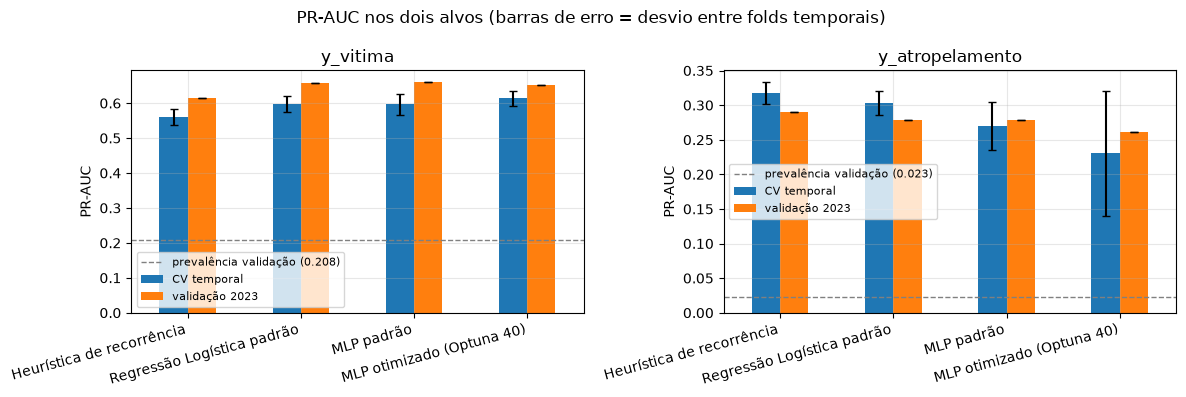

In [23]:
ordem = ["heuristica_recorrencia", "regressao_logistica", "mlp_padrao", "mlp_otimizado"]
fig, axs = plt.subplots(1, 2, figsize=(12, 4))
for ax, alvo, prev in [(axs[0], ALVO, yv.mean()), (axs[1], ALVO2, yv2.mean())]:
    vals = pd.DataFrame({NOMES[n]: {"CV temporal": resultados[(alvo, n)]["cv_temporal_pr_auc_mean"],
                                    "validação 2023": resultados[(alvo, n)]["val_pr_auc"]} for n in ordem}).T
    erro = pd.DataFrame({"CV temporal": [resultados[(alvo, n)]["cv_temporal_pr_auc_std"] for n in ordem],
                         "validação 2023": 0}, index=vals.index)
    vals.plot.bar(ax=ax, yerr=erro, capsize=3)
    ax.axhline(prev, color="gray", ls="--", lw=1, label=f"prevalência validação ({prev:.3f})")
    ax.set(title=alvo, ylabel="PR-AUC")
    ax.legend(fontsize=8)
    plt.setp(ax.get_xticklabels(), rotation=15, ha="right")
fig.suptitle("PR-AUC nos dois alvos (barras de erro = desvio entre folds temporais)")
salvar(fig, "pr_auc_dois_alvos.png")

**Leitura do alvo secundário (`y_atropelamento`): o MLP não ganha da heurística.**

- **CV temporal (PR-AUC):** a heurística é a melhor (0,318 ± 0,016), seguida da Regressão Logística
  (0,303 ± 0,018), do MLP padrão (0,270 ± 0,035) e do MLP otimizado (0,230 ± 0,090).
- **O MLP otimizado é instável no atropelamento.** O desvio entre folds é 0,090, quatro vezes o dos
  pisos. Ele vem do fold 2022Q1, com PR-AUC de 0,084, contra 0,34 da heurística no mesmo fold. Nos
  outros folds, ele fica de 0,250 a 0,330. Com 46 positivos no trimestre validado e uma rede `128-64`
  devolvida na 1ª época com taxa de aprendizado alta, um único ajuste ruim derruba a média. Também é
  o único caso em que o k-fold estratificado dá mais que a CV temporal (+0,052), o que, com esse
  desvio, não dá para interpretar.
- **Validação de 2023 (PR-AUC):** heurística 0,290, MLP padrão 0,279, Regressão Logística 0,278 e
  MLP otimizado 0,262. A prevalência é 0,023.
- **No topo da lista**, o MLP padrão é o melhor: Recall@50 de 0,459, contra 0,401 a 0,424 dos
  outros, e precisão@50 de 0,345. Mas a diferença para a heurística (0,320) é de cerca de 1,25 acerto
  em 50 por trimestre, com 35 a 40 positivos por trimestre. Com tão poucos eventos, isso cabe no
  ruído. Aqui o teto do Recall@k é 1, e o teto da precisão@50 é 0,755 (nem um ranking perfeito
  acerta 50 com menos de 50 positivos).
- **Ressalva (`ARCHITECTURE.md`, 17.2):** a configuração foi otimizada para `y_vitima`, e o
  atropelamento tem cerca de 40 positivos por trimestre. Os resultados deste alvo são indicativos e
  só sustentam uma afirmação: nenhuma variante do MLP supera a heurística de recorrência no PR-AUC.

## 10. Tabela final e exportação

In [24]:
NOMES_ALVO = {"y_vitima": "y_vitima (principal)", "y_atropelamento": "y_atropelamento (secundário)"}
tabela2 = pd.concat({NOMES_ALVO[a]: tabela(a, ordem) for a in (ALVO, ALVO2)})
tabela2.index.names = ["alvo", "modelo"]
tabela2

CV temporal PR-AUC CV temporal ROC-AUC CV estratificado PR-AUC Δ PR-AUC estrat. − temporal Val PR-AUC Val Recall@50  \
alvo                         modelo                                                                                                                                             
y_vitima (principal)         Heurística de recorrência         0.560 ± 0.023       0.790 ± 0.016           0.541 ± 0.021                      -0.019      0.614         0.141   
                             Regressão Logística padrão        0.597 ± 0.023       0.816 ± 0.017           0.578 ± 0.020                      -0.019      0.658         0.141   
                             MLP padrão                        0.596 ± 0.029       0.816 ± 0.019           0.579 ± 0.019                      -0.017      0.661         0.141   
                             MLP otimizado (Optuna 40)         0.613 ± 0.022       0.825 ± 0.015           0.566 ± 0.043                      -0.047      0.651         0.140   
                             teto do Recall@k (validação)                                                                                                               0.147   
y_atropelamento (secundário) Heurística de recorrência         0.318 ± 0.016       0.841 ± 0.023           0.272 ± 0.050                      -0.046      0.290         0.424   
                             Regressão Logística padrão        0.303 ± 0.018       0.818 ± 0.013           0.274 ± 0.064                      -0.029      0.278         0.418   
                             MLP padrão                        0.270 ± 0.035       0.848 ± 0.016           0.255 ± 0.048                      -0.015      0.279         0.459   
                             MLP otimizado (Optuna 40)         0.230 ± 0.090       0.780 ± 0.060           0.282 ± 0.046                      +0.052      0.262         0.401   
                             teto do Recall@k (validação)                                                                                                               1.000   

                                                          Val Recall@100 Val Precisão@50 Val Precisão@100 Val ROC-AUC  
alvo                         modelo                                                                                    
y_vitima (principal)         Heurística de recorrência             0.261           0.965            0.895       0.795  
                             Regressão Logística padrão            0.264           0.965            0.907       0.818  
                             MLP padrão                            0.264           0.965            0.907       0.825  
                             MLP otimizado (Optuna 40)             0.261           0.960            0.898       0.815  
                             teto do Recall@k (validação)          0.294                                               
y_atropelamento (secundário) Heurística de recorrência             0.562           0.320            0.212       0.828  
                             Regressão Logística padrão            0.558           0.315            0.210       0.823  
                             MLP padrão                            0.597           0.345            0.225       0.848  
                             MLP otimizado (Optuna 40)             0.539           0.300            0.203       0.843  
                             teto do Recall@k (validação)          1.000

A Tabela 2 junta os dois alvos. As linhas "teto do Recall@k" mostram o maior Recall@50 e Recall@100
possíveis na validação de 2023, dado o nº de positivos por trimestre. Em `y_vitima`, todos os modelos
ficam em 0,140 a 0,141 de Recall@50 contra um teto de 0,147, com precisão@50 de 0,960 a 0,965 (48 de
50 acertos por trimestre), então o top-50 não diferencia os modelos. No top-100, a precisão@100 vai
de 0,895 (heurística) a 0,907 (Regressão Logística e MLP padrão), e o MLP otimizado fica em 0,898.

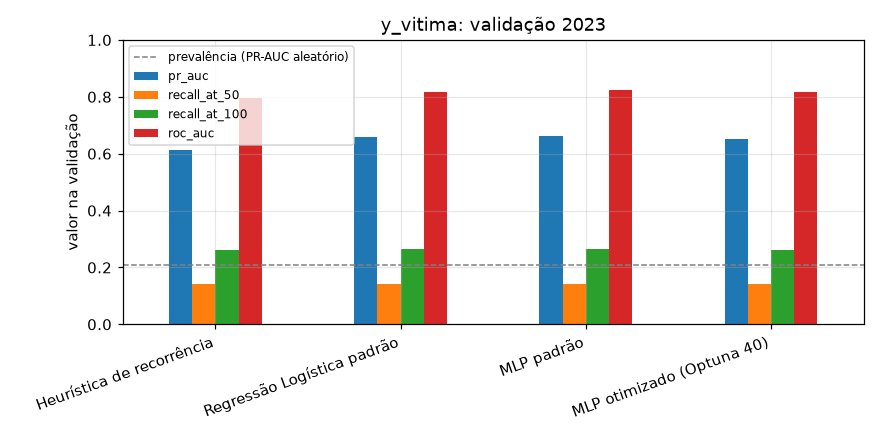

gravado: reports/experimentos/marina_mlp.csv | colunas: 27
figuras: ['comparacao_validacao_y_vitima.png', 'curva_aprendizado.png', 'curva_perda_early_stopping.png', 'optuna_melhor_acumulado.png', 'optuna_pr_auc_por_hiperparametro.png', 'permutation_importance.png', 'pr_auc_dois_alvos.png', 'pr_auc_por_alpha.png', 'pr_auc_por_arquitetura.png', 'pr_auc_por_fold.png', 'pr_auc_treino_validacao.png', 'sensibilidade_semente.png']


In [25]:
# mesmas colunas do marina_knn.csv (branch ml/knn), na mesma ordem, e as novas no fim
colunas_csv = ["cv_temporal_pr_auc_mean", "cv_temporal_pr_auc_std", "cv_temporal_roc_auc_mean", "cv_temporal_roc_auc_std",
               "cv_estratificado_pr_auc_mean", "cv_estratificado_pr_auc_std", "val_pr_auc", "val_recall_at_50",
               "val_recall_at_100", "val_roc_auc", "val_prevalencia", "val_limiar", "val_f1", "val_precisao", "val_recall"]
csv = pd.DataFrame([{"autor": AUTOR, "modelo_investigado": MODELO, "alvo": a, "configuracao": n,
                     **{c: resultados[(a, n)].get(c) for c in colunas_csv},
                     "params": str(params_melhor) if n == "mlp_otimizado" else
                               ("pipeline.modelos()" if n != "heuristica_recorrencia" else "acidentes_vitima_4t + acidentes_4t/1000"),
                     "run_id_mlflow": resultados[(a, n)].get("run_id")}
                    for a in (ALVO, ALVO2) for n in ordem])
csv["tempo_busca_optuna_s"] = round(tempo_busca, 1)
csv["n_trials_optuna"] = n_feitos
csv["val_precisao_at_50"] = [resultados[(a, n)]["val_precisao_at_50"] for a in (ALVO, ALVO2) for n in ordem]
csv["val_precisao_at_100"] = [resultados[(a, n)]["val_precisao_at_100"] for a in (ALVO, ALVO2) for n in ordem]
csv["val_teto_recall_at_50"] = [TETO[(a, 50)] for a in (ALVO, ALVO2) for n in ordem]
csv["val_teto_recall_at_100"] = [TETO[(a, 100)] for a in (ALVO, ALVO2) for n in ordem]
csv.to_csv(EXP / f"{AUTOR}_{MODELO}.csv", index=False)

barras = pd.DataFrame({NOMES[n]: {k.removeprefix("val_"): resultados[(ALVO, n)][k] for k in
                                  ["val_pr_auc", "val_recall_at_50", "val_recall_at_100", "val_roc_auc", "val_prevalencia"]}
                       for n in ordem}).T
metricas.barras_comparacao(barras, FIG / "comparacao_validacao_y_vitima.png", f"{ALVO}: validação 2023")
display(Image(FIG / "comparacao_validacao_y_vitima.png"))
print("gravado:", (EXP / f"{AUTOR}_{MODELO}.csv").relative_to(RAIZ), "| colunas:", len(csv.columns))
print("figuras:", sorted(p.name for p in FIG.glob("*.png")))

## Conclusões

- **Desempenho no alvo principal (`y_vitima`).** O MLP otimizado (`128-64`, `alpha` ≈ 0,0023,
  `learning_rate_init` ≈ 0,0074) tem PR-AUC de 0,613 ± 0,022 na CV temporal e de 0,651 na validação
  de 2023, contra uma prevalência de 0,149 e 0,208. O MLP padrão tem 0,596 ± 0,029 e 0,661.
- **Contra a Regressão Logística: empate.** Na CV temporal, o otimizado fica +0,016 acima (0,613
  contra 0,597), +0,011 na média de 5 sementes. Isso é mais que o desvio entre sementes (0,005), mas
  menos que o desvio entre folds (0,022). Na validação de 2023, ele fica *abaixo* (0,651 contra
  0,658; −0,005 na média das sementes, do tamanho do desvio entre sementes). O MLP padrão empata nas
  duas (−0,001 e +0,003). A vantagem na CV não se repete em 2023, então ela não é conclusiva.
- **Contra a heurística de recorrência: ganho real e moderado.** +0,053 na CV (+0,048 na média das
  sementes) e +0,037 na validação (+0,039 na média). Isso é cerca de 2 vezes o desvio entre folds e
  de 8 a 10 vezes o desvio entre sementes.
- **No topo da lista, nada muda.** O Recall@50 de todos fica em 0,140 a 0,141 contra um teto de
  0,147, e a precisão@50 em 0,960 a 0,965. A precisão@100 do MLP otimizado (0,898) fica entre a da
  heurística (0,895) e a da Regressão Logística (0,907).
- **Por que o MLP não vai além da Regressão Logística.** O `early_stopping` mede acurácia numa
  validação interna sorteada e devolve os pesos da melhor época. Na melhor configuração, essa época
  foi a 1ª. O modelo final está no nível de ajuste da Regressão Logística (PR-AUC de treino 0,608
  contra 0,595), o `alpha` quase não tem efeito (0,610 a 0,612 de 1e-5 a 1e-1), e as configurações
  que treinam mais épocas (`alpha=1e-2`, arquitetura `64`) se ajustam mais ao treino e pioram em
  2023. A importância por permutação aponta o mesmo sinal da heurística, o histórico de 4 trimestres.
- **Busca.** Os 40 trials levaram 4,9 min (limite de 30 min, sem corte). Eles ganharam +0,003 na CV
  sobre os 10 trials do repositório e perderam 0,009 na validação. O melhor `learning_rate_init`
  ficou colado na borda de cima do espaço, e a melhor arquitetura é a maior opção. O espaço não foi
  ampliado.
- **Custo.** O ajuste leva cerca de 2,5 s, o mesmo que a Regressão Logística, e a predição menos de
  0,1 s. O MLP não traz coeficientes interpretáveis e depende da semente, então a Regressão
  Logística entrega o mesmo desempenho com menos complexidade.
- **Alvo secundário (`y_atropelamento`).** Nenhuma variante do MLP supera a heurística (CV de 0,318;
  validação de 0,290). O otimizado é instável (0,230 ± 0,090 na CV, com um fold em 0,084). Isso vale
  com a ressalva de cerca de 40 positivos por trimestre.